In [ ]:
import os

dataset_path = "/kaggle/input"

for root, dirs, files in os.walk(dataset_path):
    print(root, "Files:", len(files))
    if root.count(os.sep) > 5:
        dirs[:] = []

Load Dataset

In [ ]:
import pandas as pd
import os

BASE_PATH = (
    "/kaggle/input/competitions/"
    "siim-isic-melanoma-classification"
)

train_csv = os.path.join(BASE_PATH, "train.csv")

df = pd.read_csv(train_csv)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nClass distribution:")
print(df["target"].value_counts())

print("\nClass percentages:")
print(df["target"].value_counts(normalize=True) * 100)

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

IMAGE_PATH = os.path.join(BASE_PATH, "jpeg/train")

samples = df.groupby("target", group_keys=False).head(3)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for row_index, (_, item) in enumerate(samples.iterrows()):
    image_file = os.path.join(
        IMAGE_PATH,
        item["image_name"] + ".jpg"
    )

    image = Image.open(image_file).convert("RGB")

    ax = axes[row_index // 3, row_index % 3]
    ax.imshow(image)
    ax.set_title(
        "Melanoma" if item["target"] == 1
        else "Non-melanoma"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

PREPARE DATASET CORRECTLY

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42

# Verify required columns and identifiers
required = ["image_name", "patient_id", "target"]
assert df[required].notna().all().all()
assert df["image_name"].is_unique

# Stratified, patient-disjoint partitioning
# 5 folds -> 20% test; remaining folds -> 60% train, 20% val, 20% test
# This is a reproducible 60/20/20 split.
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

y = df["target"]
groups = df["patient_id"]

train_val_idx, test_idx = next(
    sgkf.split(df, y, groups)
)

train_val_df = df.iloc[train_val_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

sgkf_inner = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=SEED + 1
)

inner_train_idx, inner_val_idx = next(
    sgkf_inner.split(
        train_val_df,
        train_val_df["target"],
        train_val_df["patient_id"]
    )
)

train_df = train_val_df.iloc[inner_train_idx].copy()
val_df = train_val_df.iloc[inner_val_idx].copy()

print("Split results:")

for name, split in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        name,
        "Images:", len(split),
        "Melanoma:", int(split["target"].sum()),
        "Patients:", split["patient_id"].nunique()
    )

# Check patient leakage
assert set(train_df.patient_id).isdisjoint(val_df.patient_id)
assert set(train_df.patient_id).isdisjoint(test_df.patient_id)
assert set(val_df.patient_id).isdisjoint(test_df.patient_id)

print("\nPatient-level leakage check passed!")

# Save reproducible splits
train_df.to_csv("/kaggle/working/train_split.csv", index=False)
val_df.to_csv("/kaggle/working/val_split.csv", index=False)
test_df.to_csv("/kaggle/working/test_split.csv", index=False)

IMPORT LIBRARIES AND CONFIGURE GPU

In [ ]:
import os
import torch
import numpy as np
import random

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

IMAGE_DIR = (
    "/kaggle/input/competitions/"
    "siim-isic-melanoma-classification/jpeg/train"
)

assert os.path.isdir(IMAGE_DIR)

DEFINE IMAGE TRANNSFORMATIONS

In [ ]:
IMG_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=20),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

CREATE CUSTOM DATASET CLASS

In [ ]:
class ISICDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image_path = os.path.join(
            self.image_dir,
            row["image_name"] + ".jpg"
        )

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(
            int(row["target"]),
            dtype=torch.long
        )

        return image, label


train_dataset = ISICDataset(
    train_df, IMAGE_DIR, train_transform
)

val_dataset = ISICDataset(
    val_df, IMAGE_DIR, eval_transform
)

test_dataset = ISICDataset(
    test_df, IMAGE_DIR, eval_transform
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Create DataLoaders _PHASE2

In [ ]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Batch positive samples:", labels.sum().item())

FIX DATALOADER ISSUE

In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("DataLoaders recreated successfully")

LOAD PRETRAINED RESNNET18

In [ ]:
import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

# Download pretrained weights on first use
weights = ResNet18_Weights.DEFAULT

model = resnet18(weights=weights)

# Replace classification head with one binary output
model.fc = nn.Linear(
    model.fc.in_features,
    1
)

model = model.to(device)

print("Model: ResNet18")
print("Device:", device)
print(
    "Total parameters:",
    sum(p.numel() for p in model.parameters())
)

Handle class imbalance

In [ ]:
import numpy as np
import torch.optim as optim

positive_count = int(train_df["target"].sum())
negative_count = len(train_df) - positive_count

imbalance_ratio = negative_count / positive_count

positive_weight = np.sqrt(imbalance_ratio)

print("Melanoma:", positive_count)
print("Non-melanoma:", negative_count)
print("Imbalance ratio:", round(imbalance_ratio, 2))
print("Positive weight:", round(positive_weight, 2))

criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [positive_weight],
        dtype=torch.float32,
        device=device
    )
)

optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

In [ ]:
import torch
import numpy as np
from tqdm.auto import tqdm
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    recall_score,
    confusion_matrix
)

def train_one_epoch(model, loader):
    model.train()
    total_loss = 0.0

    for images, labels in tqdm(loader, desc="Training"):
        images = images.to(device)
        labels = labels.float().unsqueeze(1).to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    return total_loss / len(loader.dataset)


@torch.no_grad()
def validate(model, loader):
    model.eval()

    probs_list = []
    labels_list = []

    for images, labels in tqdm(loader, desc="Validation"):
        images = images.to(device)

        outputs = model(images)
        probs = torch.sigmoid(outputs).flatten()

        probs_list.extend(probs.cpu().numpy())
        labels_list.extend(labels.numpy())

    y_true = np.array(labels_list)
    y_prob = np.array(probs_list)

    y_pred = (y_prob >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "pr_auc": average_precision_score(y_true, y_prob),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "specificity": tn / (tn + fp),
        "false_negatives": int(fn)
    }

print("Training functions ready!")

Inspect the validation threshold -OPTIONAL

In [ ]:
import torch
import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

checkpoint = torch.load(
    "/kaggle/working/best_resnet18.pth",
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

all_probs = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        logits = model(images)
        probs = torch.sigmoid(logits).flatten()

        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(labels.numpy())

y_true = np.array(all_labels)
y_prob = np.array(all_probs)

results = []

for threshold in [0.01, 0.03, 0.05, 0.10, 0.20, 0.30, 0.50]:
    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    results.append({
        "Threshold": threshold,
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Specificity": tn / (tn + fp),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "False Negatives": fn,
        "False Positives": fp,
        "F1": f1_score(y_true, y_pred, zero_division=0)
    })

display(pd.DataFrame(results).round(4))

START TRAINING

In [ ]:
import os
import pandas as pd

EPOCHS = 10
PATIENCE = 4

best_pr_auc = -1
epochs_without_improvement = 0
history = []

CHECKPOINT_PATH = "/kaggle/working/best_resnet18.pth"

for epoch in range(EPOCHS):

    print(f"\n========== Epoch {epoch+1}/{EPOCHS} ==========")

    train_loss = train_one_epoch(model, train_loader)
    metrics = validate(model, val_loader)

    scheduler.step(metrics["pr_auc"])

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        **metrics
    })

    print(f"Train loss: {train_loss:.4f}")
    print(f"Validation PR-AUC: {metrics['pr_auc']:.4f}")
    print(f"Validation ROC-AUC: {metrics['roc_auc']:.4f}")
    print(f"Melanoma recall: {metrics['recall']:.4f}")
    print(f"Specificity: {metrics['specificity']:.4f}")
    print(f"False negatives: {metrics['false_negatives']}")

    if metrics["pr_auc"] > best_pr_auc + 1e-4:
        best_pr_auc = metrics["pr_auc"]
        epochs_without_improvement = 0

        torch.save({
            "model_state_dict": model.state_dict(),
            "epoch": epoch + 1,
            "validation_pr_auc": best_pr_auc,
            "image_size": IMG_SIZE,
            "positive_weight": float(positive_weight)
        }, CHECKPOINT_PATH)

        print("Best model saved!")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

history_df = pd.DataFrame(history)
history_df.to_csv(
    "/kaggle/working/resnet18_history.csv",
    index=False
)

print("\nTraining complete!")
print("Best validation PR-AUC:", round(best_pr_auc, 4))
print("Saved model:", CHECKPOINT_PATH)

In [ ]:
import os
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

# Load BEST checkpoint (Epoch 6)
path = "/kaggle/working/best_resnet18.pth"

assert os.path.exists(path), "Checkpoint missing!"

checkpoint = torch.load(
    path,
    map_location=device,
    weights_only=False
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Loaded best epoch:", checkpoint["epoch"])

# Validation predictions
all_probs = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        logits = model(images)

        probs = torch.sigmoid(logits).flatten()

        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(labels.numpy())

y_true = np.array(all_labels)
y_prob = np.array(all_probs)

print("PR-AUC:", average_precision_score(y_true, y_prob))
print("ROC-AUC:", roc_auc_score(y_true, y_prob))

# Evaluate multiple thresholds
results = []

for threshold in [
    0.01, 0.02, 0.03, 0.05,
    0.10, 0.15, 0.20, 0.25,
    0.30, 0.40, 0.50
]:
    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    results.append({
        "Threshold": threshold,
        "Recall": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "False Negatives": fn,
        "False Positives": fp,
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(results)

display(threshold_df.round(4))

threshold_df.to_csv(
    "/kaggle/working/resnet18_threshold_analysis.csv",
    index=False
)

In [ ]:
import os

files = [
    "resnet18_validation_predictions.csv",
    "resnet18_threshold_analysis.csv"
]

for name in files:
    path = f"/kaggle/working/{name}"
    if os.path.exists(path):
        print(name, "SAVED", os.path.getsize(path), "bytes")
    else:
        print(name, "NOT SAVED")

In [ ]:
import torch

checkpoint_path = checkpoints[0]

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint loaded successfully!")
print("Best epoch:", checkpoint["epoch"])
print("Validation PR-AUC:", checkpoint["validation_pr_auc"])

In [ ]:
import os
import glob

# Search saved notebook outputs
checkpoints = glob.glob(
    "/kaggle/input/**/best_resnet18.pth",
    recursive=True
)

# Also check the current working directory
working_path = "/kaggle/working/best_resnet18.pth"

if os.path.isfile(working_path):
    checkpoints.insert(0, working_path)

print("Checkpoints found:", len(checkpoints))

for path in checkpoints:
    print("FOUND:", path)
    print("Size:", round(os.path.getsize(path) / 1024**2, 2), "MB")

In [ ]:
# Restore trained weights
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print("Best ResNet18 restored successfully!")

SAVE PREDICTIONS

In [ ]:
import os
import glob

paths = glob.glob(
    "/kaggle/input/**/best_resnet18.pth",
    recursive=True
)

for path in paths:
    print("FOUND:", path)

print("Total checkpoints:", len(paths))

In [ ]:
import os

path = (
    "/kaggle/input/notebooks/mahjabinhossain/"
    "notebooka2fd61ea28/best_resnet18.pth"
)

print("Checkpoint available:", os.path.isfile(path))

new work starting

In [ ]:
import torch

checkpoint = torch.load(
    path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint loaded successfully!")
print("Best epoch:", checkpoint["epoch"])
print("Validation PR-AUC:", checkpoint["validation_pr_auc"])

load resnet again for validation

In [ ]:
import torch.nn as nn
from torchvision.models import resnet18

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 1)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print("ResNet18 restored successfully!")

Restore your validation dataset

In [ ]:
import os
import pandas as pd
from PIL import Image

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

BASE_PATH = (
    "/kaggle/input/competitions/"
    "siim-isic-melanoma-classification"
)

IMAGE_DIR = os.path.join(BASE_PATH, "jpeg/train")

# Use the SAME saved validation split
val_path = "/kaggle/working/val_split.csv"

if not os.path.exists(val_path):
    import glob

    matches = glob.glob(
        "/kaggle/input/notebooks/mahjabinhossain/"
        "notebooka2fd61ea28/**/val_split.csv",
        recursive=True
    )

    assert matches, "Saved validation split not found!"
    val_path = matches[0]

val_df = pd.read_csv(val_path)

# Same preprocessing used during training
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class ISICDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image_path = os.path.join(
            self.image_dir,
            row["image_name"] + ".jpg"
        )

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        return (
            self.transform(image),
            int(row["target"])
        )

val_dataset = ISICDataset(
    val_df,
    IMAGE_DIR,
    eval_transform
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

print("Validation images:", len(val_dataset))
print("Melanoma images:", int(val_df["target"].sum()))
print("Validation DataLoader ready!")

Generate and save predictions

In [ ]:
import torch
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score
)

model.eval()

all_probs = []
all_labels = []

with torch.inference_mode():
    for images, labels in tqdm(
        val_loader,
        desc="Validation inference"
    ):
        images = images.to(device)

        logits = model(images)
        probs = torch.sigmoid(logits).flatten()

        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(labels.numpy())

y_true = np.array(all_labels)
y_prob = np.array(all_probs)

print("PR-AUC:", average_precision_score(y_true, y_prob))
print("ROC-AUC:", roc_auc_score(y_true, y_prob))

# Ensure saved predictions correspond to correct images
assert len(val_df) == len(y_true) == len(y_prob)
assert np.array_equal(
    val_df["target"].to_numpy(),
    y_true
), "Validation labels are not aligned!"

prediction_df = pd.DataFrame({
    "image_name": val_df["image_name"].to_numpy(),
    "patient_id": val_df["patient_id"].to_numpy(),
    "actual_label": y_true,
    "model_score": y_prob
})

output_path = (
    "/kaggle/working/"
    "resnet18_validation_predictions.csv"
)

prediction_df.to_csv(output_path, index=False)

print("Predictions saved successfully!")
print("File:", output_path)
print("Rows:", len(prediction_df))

In [ ]:
calculate thresholds directly from csv

In [ ]:
import pandas as pd
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    f1_score
)

df_pred = pd.read_csv(
    "/kaggle/working/resnet18_validation_predictions.csv"
)

y_true = df_pred["actual_label"].to_numpy()
y_prob = df_pred["model_score"].to_numpy()

results = []

for threshold in [
    0.01, 0.02, 0.03, 0.05,
    0.10, 0.15, 0.20, 0.25,
    0.30, 0.40, 0.50
]:
    y_pred = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    results.append({
        "Threshold": threshold,
        "Recall": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "False Negatives": fn,
        "False Positives": fp,
        "F1": f1_score(y_true, y_pred, zero_division=0)
    })

threshold_df = pd.DataFrame(results)

display(threshold_df.round(4))

threshold_df.to_csv(
    "/kaggle/working/resnet18_threshold_analysis.csv",
    index=False
)

print("Threshold analysis saved!")

checking if everything is saved

In [ ]:
import os

files = [
    "resnet18_validation_predictions.csv",
    "resnet18_threshold_analysis.csv"
]

for filename in files:
    path = f"/kaggle/working/{filename}"

    if os.path.isfile(path):
        print("SAVED:", filename)
        print("Size:", os.path.getsize(path), "bytes")
    else:
        print("MISSING:", filename)

EFFICIENT MODEL INITIALIZE

In [ ]:
import torch
import torch.nn as nn
from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights
)

weights = EfficientNet_B0_Weights.DEFAULT

efficientnet_model = efficientnet_b0(weights=weights)

efficientnet_model.classifier[1] = nn.Linear(
    efficientnet_model.classifier[1].in_features,
    1
)

print("EfficientNet-B0 initialized!")
print(
    "Total parameters:",
    sum(p.numel() for p in efficientnet_model.parameters())
)

VERIFY TRAINING DATA

In [ ]:
import os
import pandas as pd

SPLIT_DIR = "/kaggle/working"

train_path = f"{SPLIT_DIR}/train_split.csv"
val_path = f"{SPLIT_DIR}/val_split.csv"

# If not in working directory, use saved notebook outputs
if not os.path.exists(train_path):
    SPLIT_DIR = (
        "/kaggle/input/notebooks/"
        "mahjabinhossain/notebooka2fd61ea28"
    )
    train_path = f"{SPLIT_DIR}/train_split.csv"
    val_path = f"{SPLIT_DIR}/val_split.csv"

train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Training melanoma:", train_df["target"].sum())
print("Validation melanoma:", val_df["target"].sum())

assert set(train_df.patient_id).isdisjoint(
    set(val_df.patient_id)
)

print("Patient leakage check passed!")

EXPECTED DEVICE

In [ ]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

VERIFY EFFICIENTNET IS ON GPU

In [ ]:
efficientnet_model = efficientnet_model.to(device)

print(
    "Model device:",
    next(efficientnet_model.parameters()).device
)

CONFIGURE LOSS, OPTIMIZER, SCHEDULER

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

# Class imbalance based on training data
positive_count = int(train_df["target"].sum())
negative_count = len(train_df) - positive_count

positive_weight = np.sqrt(
    negative_count / positive_count
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [positive_weight],
        dtype=torch.float32,
        device=device
    )
)

optimizer = optim.AdamW(
    efficientnet_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

# Mixed precision for Tesla T4
scaler = torch.amp.GradScaler("cuda")

print("Positive weight:", round(positive_weight, 2))
print("Loss function ready!")
print("Optimizer ready!")
print("Scheduler ready!")
print("Mixed precision ready!")

Verify your training setup

In [ ]:
print("Device:", device)
print("Model device:", next(efficientnet_model.parameters()).device)
print("Training images:", len(train_loader.dataset))
print("Validation images:", len(val_loader.dataset))
print("Batch size:", train_loader.batch_size)

RESTORE DATALOADERS

In [ ]:
import os
import pandas as pd
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

# Dataset image location
IMAGE_DIR = (
    "/kaggle/input/competitions/"
    "siim-isic-melanoma-classification/jpeg/train"
)

# Load existing split files if not already loaded
if "train_df" not in globals() or "val_df" not in globals():

    split_dir = (
        "/kaggle/input/notebooks/"
        "mahjabinhossain/notebooka2fd61ea28"
    )

    train_df = pd.read_csv(
        os.path.join(split_dir, "train_split.csv")
    )

    val_df = pd.read_csv(
        os.path.join(split_dir, "val_split.csv")
    )

# Transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Dataset class
class ISICDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image_path = os.path.join(
            self.image_dir,
            row["image_name"] + ".jpg"
        )

        with Image.open(image_path) as img:
            image = img.convert("RGB")
            image = self.transform(image)

        return image, int(row["target"])


# Create datasets
train_dataset = ISICDataset(
    train_df, IMAGE_DIR, train_transform
)

val_dataset = ISICDataset(
    val_df, IMAGE_DIR, val_transform
)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("DataLoaders created successfully!")
print("Train:", len(train_loader.dataset))
print("Validation:", len(val_loader.dataset))

In [ ]:
print("Device:", device)
print(
    "Model device:",
    next(efficientnet_model.parameters()).device
)
print("Training images:", len(train_loader.dataset))
print("Validation images:", len(val_loader.dataset))
print("Batch size:", train_loader.batch_size)

VERIFY YOUR OPTIMIZER IS READY

In [ ]:
required = [
    "efficientnet_model",
    "train_loader",
    "val_loader",
    "criterion",
    "optimizer",
    "scheduler",
    "scaler",
    "device"
]

missing = [x for x in required if x not in globals()]

print("Missing:", missing)
print("GPU:", device)

Create EfficientNet training functions

In [ ]:
import torch
import numpy as np
from tqdm.auto import tqdm

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

def train_efficientnet_epoch():
    efficientnet_model.train()
    total_loss = 0.0

    for images, labels in tqdm(
        train_loader,
        desc="EfficientNet Training"
    ):
        images = images.to(device, non_blocking=True)
        labels = labels.float().unsqueeze(1).to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(device_type="cuda"):
            logits = efficientnet_model(images)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * images.size(0)

    return total_loss / len(train_loader.dataset)


@torch.inference_mode()
def validate_efficientnet():
    efficientnet_model.eval()

    all_probs = []
    all_labels = []

    for images, labels in tqdm(
        val_loader,
        desc="EfficientNet Validation"
    ):
        images = images.to(device, non_blocking=True)

        with torch.amp.autocast(device_type="cuda"):
            logits = efficientnet_model(images)

        probs = torch.sigmoid(logits.float()).flatten()

        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(labels.numpy())

    y_true = np.array(all_labels, dtype=int)
    y_prob = np.array(all_probs)

    y_pred = (y_prob >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "pr_auc": float(average_precision_score(y_true, y_prob)),
        "roc_auc": float(roc_auc_score(y_true, y_prob)),
        "recall": float(tp / (tp + fn)),
        "specificity": float(tn / (tn + fp)),
        "false_negatives": int(fn),
        "false_positives": int(fp)
    }

print("EfficientNet training functions ready!")

Start resumable EfficientNet training

In [ ]:
import os
import torch
import pandas as pd

EPOCHS = 3

BEST_PATH = "/kaggle/working/efficientnet_b0_best.pth"
LATEST_PATH = "/kaggle/working/efficientnet_b0_latest.pth"
HISTORY_PATH = "/kaggle/working/efficientnet_b0_history.csv"

start_epoch = 0
best_pr_auc = -1.0
history = []

# Resume from complete checkpoint if available
if os.path.exists(LATEST_PATH):

    checkpoint = torch.load(
        LATEST_PATH,
        map_location=device,
        weights_only=True
    )

    efficientnet_model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    scheduler.load_state_dict(
        checkpoint["scheduler_state_dict"]
    )

    scaler.load_state_dict(
        checkpoint["scaler_state_dict"]
    )

    start_epoch = int(checkpoint["epoch"])
    best_pr_auc = float(checkpoint["best_pr_auc"])
    history = checkpoint.get("history", [])

    print("Resuming from completed epoch:", start_epoch)

else:
    print("Starting fresh EfficientNet-B0 training.")

for epoch in range(start_epoch, EPOCHS):

    print(f"\n========== Epoch {epoch+1}/{EPOCHS} ==========")

    train_loss = train_efficientnet_epoch()

    metrics = validate_efficientnet()

    scheduler.step(metrics["pr_auc"])

    history.append({
        "epoch": epoch + 1,
        "train_loss": float(train_loss),
        **metrics
    })

    print("Training loss:", round(train_loss, 4))
    print("PR-AUC:", round(metrics["pr_auc"], 4))
    print("ROC-AUC:", round(metrics["roc_auc"], 4))
    print("Melanoma recall:", round(metrics["recall"], 4))
    print("Specificity:", round(metrics["specificity"], 4))
    print("False negatives:", metrics["false_negatives"])

    if metrics["pr_auc"] > best_pr_auc:

        best_pr_auc = metrics["pr_auc"]

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": efficientnet_model.state_dict(),
            "validation_pr_auc": float(best_pr_auc)
        }, BEST_PATH)

        print("Best EfficientNet model saved!")

    # Save complete training state
    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": efficientnet_model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "best_pr_auc": float(best_pr_auc),
        "history": history
    }, LATEST_PATH)

    pd.DataFrame(history).to_csv(
        HISTORY_PATH,
        index=False
    )

    print("Latest checkpoint and history saved!")

print("\nEfficientNet training completed!")
print("Best PR-AUC:", round(best_pr_auc, 4))

Generate EfficientNet validation predictions

In [ ]:
import os
import numpy as np
import pandas as pd
import torch

from tqdm.auto import tqdm
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score
)

# Load the best checkpoint from Epoch 3
checkpoint_path = "/kaggle/working/efficientnet_b0_best.pth"

assert os.path.isfile(checkpoint_path), "Best checkpoint not found!"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

efficientnet_model.load_state_dict(
    checkpoint["model_state_dict"]
)

efficientnet_model = efficientnet_model.to(device)
efficientnet_model.eval()

all_probs = []
all_labels = []

with torch.inference_mode():
    for images, labels in tqdm(
        val_loader,
        desc="EfficientNet Validation Inference"
    ):
        images = images.to(device)

        with torch.amp.autocast(
            device_type="cuda",
            enabled=(device.type == "cuda")
        ):
            logits = efficientnet_model(images)

        probs = torch.sigmoid(logits.float()).flatten()

        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(labels.numpy())

y_true_eff = np.array(all_labels, dtype=int)
y_prob_eff = np.array(all_probs)

assert len(y_true_eff) == len(val_df)
assert np.array_equal(
    y_true_eff,
    val_df["target"].to_numpy()
)

prediction_df = pd.DataFrame({
    "image_name": val_df["image_name"].to_numpy(),
    "patient_id": val_df["patient_id"].to_numpy(),
    "actual_label": y_true_eff,
    "model_score": y_prob_eff
})

output_path = (
    "/kaggle/working/"
    "efficientnet_b0_validation_predictions.csv"
)

prediction_df.to_csv(output_path, index=False)

print("PR-AUC:", average_precision_score(y_true_eff, y_prob_eff))
print("ROC-AUC:", roc_auc_score(y_true_eff, y_prob_eff))
print("Predictions saved:", output_path)
print("Rows:", len(prediction_df))

locate both predictions csv

In [ ]:
import os

# Check your current working directory
files = [
    "resnet18_validation_predictions.csv",
    "efficientnet_b0_validation_predictions.csv"
]

for filename in files:
    path = f"/kaggle/working/{filename}"

    print(
        filename,
        "FOUND" if os.path.exists(path) else "NOT FOUND"
    )

Load both models' predictions

In [ ]:
import pandas as pd
import os

BASE_DIR = "/kaggle/working"

resnet_path = os.path.join(
    BASE_DIR,
    "resnet18_validation_predictions.csv"
)

efficientnet_path = os.path.join(
    BASE_DIR,
    "efficientnet_b0_validation_predictions.csv"
)

resnet_df = pd.read_csv(resnet_path)
efficientnet_df = pd.read_csv(efficientnet_path)

print("ResNet18 rows:", len(resnet_df))
print("EfficientNet rows:", len(efficientnet_df))

C****ompare models and create a two-model ensemble**

In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

# Merge predictions by image ID, not row position
comparison = resnet_df.merge(
    efficientnet_df,
    on="image_name",
    suffixes=("_resnet", "_efficientnet"),
    validate="one_to_one"
)

assert len(comparison) == 6043, "Some image IDs do not match!"

assert np.array_equal(
    comparison["actual_label_resnet"].to_numpy(),
    comparison["actual_label_efficientnet"].to_numpy()
), "Label mismatch between models!"

y_true = comparison["actual_label_resnet"].to_numpy()

resnet_probs = comparison["model_score_resnet"].to_numpy()
efficientnet_probs = comparison["model_score_efficientnet"].to_numpy()

# Simple average ensemble
ensemble_probs = (
    resnet_probs + efficientnet_probs
) / 2

models = {
    "ResNet18": resnet_probs,
    "EfficientNet-B0": efficientnet_probs,
    "Ensemble": ensemble_probs
}

results = []

for name, probs in models.items():

    pr_auc = average_precision_score(y_true, probs)
    roc_auc = roc_auc_score(y_true, probs)

    # Research operating point: at least 95% sensitivity
    thresholds = np.unique(probs)

    candidates = []

    for threshold in thresholds:
        preds = (probs >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true, preds, labels=[0, 1]
        ).ravel()

        sensitivity = tp / (tp + fn)
        specificity = tn / (tn + fp)

        if sensitivity >= 0.95:
            candidates.append(
                (specificity, threshold, sensitivity, fp, fn)
            )

    if candidates:
        best = max(candidates, key=lambda x: x[0])

        results.append({
            "Model": name,
            "PR-AUC": pr_auc,
            "ROC-AUC": roc_auc,
            "Threshold": best[1],
            "Sensitivity": best[2],
            "Specificity": best[0],
            "False Positives": best[3],
            "False Negatives": best[4]
        })

results_df = pd.DataFrame(results)

display(results_df.round(4))

results_df.to_csv(
    "/kaggle/working/model_comparison.csv",
    index=False
)

comparison["ensemble_score"] = ensemble_probs

comparison.to_csv(
    "/kaggle/working/ensemble_validation_predictions.csv",
    index=False
)

print("Model comparison completed!")

compare missed melanomas

In [ ]:
import pandas as pd
import numpy as np

# Use the existing aligned comparison DataFrame
thresholds = {
    "ResNet18": 0.0113,
    "EfficientNet-B0": 0.0058,
    "Ensemble": 0.0114
}

scores = {
    "ResNet18": comparison["model_score_resnet"].to_numpy(),
    "EfficientNet-B0": comparison["model_score_efficientnet"].to_numpy(),
    "Ensemble": comparison["ensemble_score"].to_numpy()
}

y_true = comparison["actual_label_resnet"].to_numpy()

for model_name, probs in scores.items():
    threshold = thresholds[model_name]

    missed = comparison[
        (y_true == 1) & (probs < threshold)
    ]

    print(f"\n{model_name}: {len(missed)} missed melanomas")
    print(missed["image_name"].tolist())

# Save detailed predictions for further analysis
comparison.to_csv(
    "/kaggle/working/detailed_model_comparison.csv",
    index=False
)

print("\nDetailed comparison saved!")

investigate missed melanoma cases

In [ ]:
import numpy as np
import pandas as pd

# Retrieve exact thresholds from model comparison
exact_thresholds = dict(
    zip(results_df["Model"], results_df["Threshold"])
)

scores = {
    "ResNet18": comparison["model_score_resnet"].to_numpy(),
    "EfficientNet-B0": comparison["model_score_efficientnet"].to_numpy(),
    "Ensemble": comparison["ensemble_score"].to_numpy()
}

positive_mask = (
    comparison["actual_label_resnet"].to_numpy() == 1
)

missed_sets = {}

for name, probs in scores.items():
    threshold = exact_thresholds[name]

    missed_mask = positive_mask & (probs < threshold)

    missed_sets[name] = set(
        comparison.loc[missed_mask, "image_name"]
    )

    print(
        name,
        "Threshold:", threshold,
        "Missed:", len(missed_sets[name])
    )

common_missed = set.intersection(*missed_sets.values())

print("\nMissed by all models:")
print(sorted(common_missed))

investigate 2

In [ ]:
import pandas as pd

# Images missed by at least one model
all_missed = set.union(*missed_sets.values())

metadata_path = (
    "/kaggle/input/competitions/"
    "siim-isic-melanoma-classification/train.csv"
)

metadata = pd.read_csv(metadata_path)

difficult_cases = metadata[
    metadata["image_name"].isin(all_missed)
].copy()

# Identify which models missed each image
for model_name, missed_ids in missed_sets.items():
    difficult_cases[
        "missed_" + model_name.replace("-", "_")
    ] = difficult_cases["image_name"].isin(missed_ids)

columns = [
    "image_name",
    "patient_id",
    "sex",
    "age_approx",
    "anatom_site_general_challenge",
    "diagnosis",
    "target",
    "missed_ResNet18",
    "missed_EfficientNet_B0",
    "missed_Ensemble"
]

display(difficult_cases[columns])

difficult_cases.to_csv(
    "/kaggle/working/difficult_melanoma_cases.csv",
    index=False
)

print("Difficult melanoma metadata saved!")
print("Unique difficult images:", len(difficult_cases))

see the scores of missing

In [ ]:
import pandas as pd
import numpy as np

# Use exact thresholds from previous analysis
thresholds = dict(
    zip(results_df["Model"], results_df["Threshold"])
)

# Select difficult melanoma images
difficult_scores = comparison[
    comparison["image_name"].isin(all_missed)
].copy()

difficult_scores = difficult_scores[
    [
        "image_name",
        "patient_id_resnet",
        "model_score_resnet",
        "model_score_efficientnet",
        "ensemble_score"
    ]
].copy()

difficult_scores.columns = [
    "image_name",
    "patient_id",
    "ResNet18_score",
    "EfficientNet_score",
    "Ensemble_score"
]

# Add missed flags using exact thresholds
difficult_scores["ResNet18_missed"] = (
    difficult_scores["ResNet18_score"]
    < thresholds["ResNet18"]
)

difficult_scores["EfficientNet_missed"] = (
    difficult_scores["EfficientNet_score"]
    < thresholds["EfficientNet-B0"]
)

difficult_scores["Ensemble_missed"] = (
    difficult_scores["Ensemble_score"]
    < thresholds["Ensemble"]
)

display(difficult_scores.round(6))

difficult_scores.to_csv(
    "/kaggle/working/difficult_melanoma_scores.csv",
    index=False
)

print("Difficult melanoma scores saved!")

In [ ]:
import os
import hashlib
import pandas as pd
from PIL import Image
import numpy as np

IMAGE_DIR = (
    "/kaggle/input/competitions/"
    "siim-isic-melanoma-classification/jpeg/train"
)

image_ids = [
    "ISIC_2607827",
    "ISIC_9967383",
    "ISIC_6352565",
    "ISIC_6584579",
    "ISIC_2979268",
    "ISIC_6539127",
    "ISIC_8355446"
]

records = []

for image_id in image_ids:
    path = os.path.join(IMAGE_DIR, image_id + ".jpg")

    with open(path, "rb") as f:
        file_hash = hashlib.sha256(f.read()).hexdigest()

    with Image.open(path) as img:
        rgb = np.asarray(img.convert("RGB"))
        pixel_hash = hashlib.sha256(rgb.tobytes()).hexdigest()
        width, height = img.size

    records.append({
        "image_name": image_id,
        "width": width,
        "height": height,
        "file_hash": file_hash,
        "pixel_hash": pixel_hash
    })

hash_df = pd.DataFrame(records)

display(hash_df)

print("\nExact duplicate files:")
display(
    hash_df[
        hash_df.duplicated("file_hash", keep=False)
    ]
)

print("\nIdentical decoded images:")
display(
    hash_df[
        hash_df.duplicated("pixel_hash", keep=False)
    ]
)

visualize pair

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os

pairs = [
    ("ISIC_2607827", "ISIC_9967383"),
    ("ISIC_6352565", "ISIC_6584579")
]

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for row, pair in enumerate(pairs):
    for col, image_id in enumerate(pair):

        path = os.path.join(
            IMAGE_DIR,
            image_id + ".jpg"
        )

        with Image.open(path) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].set_title(image_id)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

audit all images

In [ ]:
import os
import glob
import pandas as pd

required_files = [
    "train_split.csv",
    "val_split.csv",
    "test_split.csv"
]

def find_saved_file(filename):
    # Search the current notebook outputs and attached Kaggle inputs
    paths = glob.glob(
        f"/kaggle/working/**/{filename}",
        recursive=True
    )

    paths += glob.glob(
        f"/kaggle/input/**/{filename}",
        recursive=True
    )

    if not paths:
        raise FileNotFoundError(
            f"{filename} not found. "
            "Attach the saved notebook version using "
            "Kaggle Add Input -> Notebook Outputs."
        )

    print(f"{filename}: {paths[0]}")
    return paths[0]

train_df = pd.read_csv(find_saved_file("train_split.csv"))
val_df = pd.read_csv(find_saved_file("val_split.csv"))
test_df = pd.read_csv(find_saved_file("test_split.csv"))

print("\nSplits restored successfully!")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

assert len(train_df) == 20423
assert len(val_df) == 6043
assert len(test_df) == 6660

print("All split sizes verified.")

In [ ]:
import os
import hashlib
import pandas as pd
from collections import defaultdict
from tqdm.auto import tqdm

IMAGE_DIR = (
    "/kaggle/input/competitions/"
    "siim-isic-melanoma-classification/jpeg/train"
)

# Use your existing patient-level splits
split_data = pd.concat([
    train_df.assign(split="train"),
    val_df.assign(split="validation"),
    test_df.assign(split="test")
], ignore_index=True)

assert split_data["image_name"].is_unique
assert len(split_data) == 33126

# Step 1: Collect file sizes
file_records = []

for row in tqdm(
    split_data.itertuples(index=False),
    total=len(split_data),
    desc="Checking file sizes"
):
    path = os.path.join(IMAGE_DIR, row.image_name + ".jpg")

    file_records.append({
        "image_name": row.image_name,
        "patient_id": row.patient_id,
        "target": row.target,
        "split": row.split,
        "file_size": os.path.getsize(path),
        "path": path
    })

audit_df = pd.DataFrame(file_records)

# Step 2: Hash files only when file sizes match
duplicate_size_mask = audit_df.duplicated(
    "file_size", keep=False
)

candidates = audit_df[duplicate_size_mask].copy()

def sha256_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            digest.update(chunk)

    return digest.hexdigest()

candidates["sha256"] = [
    sha256_file(path)
    for path in tqdm(
        candidates["path"],
        desc="Hashing duplicate-size candidates"
    )
]

# Step 3: Identify exact duplicate groups
duplicates = candidates[
    candidates.duplicated("sha256", keep=False)
].copy()

duplicates = duplicates.sort_values(
    ["sha256", "image_name"]
)

duplicates["duplicate_group"] = (
    duplicates.groupby("sha256", sort=True).ngroup() + 1
)

# Step 4: Check for duplicates across splits
cross_split_groups = (
    duplicates.groupby("sha256")["split"]
    .nunique()
)

cross_split_hashes = cross_split_groups[
    cross_split_groups > 1
].index

cross_split_duplicates = duplicates[
    duplicates["sha256"].isin(cross_split_hashes)
].copy()

print("Total images:", len(audit_df))
print("Images in exact duplicate groups:", len(duplicates))
print("Exact duplicate groups:", duplicates["sha256"].nunique())
print("Duplicate groups spanning splits:", len(cross_split_hashes))

display(
    duplicates[
        [
            "duplicate_group",
            "image_name",
            "patient_id",
            "target",
            "split"
        ]
    ]
)

# Save reports
duplicates.to_csv(
    "/kaggle/working/all_exact_duplicates.csv",
    index=False
)

cross_split_duplicates.to_csv(
    "/kaggle/working/cross_split_duplicates.csv",
    index=False
)

print("Duplicate audit complete.")

within sets duplication

In [ ]:
import pandas as pd

# 1. Count duplicate groups by split
split_summary = (
    duplicates.groupby("split")
    .agg(
        duplicate_images=("image_name", "count"),
        duplicate_groups=("sha256", "nunique"),
        melanoma_images=("target", "sum")
    )
    .reset_index()
)

split_summary["redundant_images"] = (
    split_summary["duplicate_images"]
    - split_summary["duplicate_groups"]
)

print("DUPLICATES BY SPLIT")
display(split_summary)

# 2. Check for conflicting labels
label_counts = (
    duplicates.groupby("sha256")["target"]
    .nunique()
)

conflicting_hashes = label_counts[
    label_counts > 1
].index

conflicting_duplicates = duplicates[
    duplicates["sha256"].isin(conflicting_hashes)
]

print(
    "\nGroups with conflicting labels:",
    len(conflicting_hashes)
)

display(
    conflicting_duplicates[
        ["image_name", "patient_id", "target", "split"]
    ]
)

# 3. Check duplicates associated with different patient IDs
patient_counts = (
    duplicates.groupby("sha256")["patient_id"]
    .nunique()
)

different_patient_hashes = patient_counts[
    patient_counts > 1
].index

print(
    "\nDuplicate groups with different patient IDs:",
    len(different_patient_hashes)
)

dedplicated csv

In [ ]:
import os
import pandas as pd

# Build a SHA-256 lookup from the completed duplicate audit
hash_lookup = duplicates.set_index("image_name")["sha256"].to_dict()

def deduplicate_split(df, split_name):
    result = df.copy()

    # Duplicate group hash for known duplicates.
    # Unique images retain their image_name as their identifier.
    result["_duplicate_key"] = result["image_name"].map(
        lambda name: hash_lookup.get(name, f"unique:{name}")
    )

    result = result.drop_duplicates(
        subset="_duplicate_key",
        keep="first"
    ).drop(columns="_duplicate_key")

    print(
        f"{split_name}: {len(df)} -> {len(result)} images "
        f"({len(df) - len(result)} duplicates removed)"
    )

    return result.reset_index(drop=True)

train_clean = deduplicate_split(train_df, "Train")
val_clean = deduplicate_split(val_df, "Validation")
test_clean = deduplicate_split(test_df, "Test")

assert len(train_clean) == 20105
assert len(val_clean) == 6001
assert len(test_clean) == 6587

# Preserve the original splits; save separate cleaned versions
train_clean.to_csv(
    "/kaggle/working/train_deduplicated.csv",
    index=False
)

val_clean.to_csv(
    "/kaggle/working/val_deduplicated.csv",
    index=False
)

test_clean.to_csv(
    "/kaggle/working/test_deduplicated.csv",
    index=False
)

print("\nDeduplicated split files saved successfully!")

In [2]:
import os

print("Attached datasets:\n")

for name in os.listdir("/kaggle/input"):
    print(name)

Attached datasets:

competitions
notebooks
datasets


In [4]:
import os

DATASET_DIR = "/kaggle/input/datasets"

for root, dirs, files in os.walk(DATASET_DIR):
    depth = root[len(DATASET_DIR):].count(os.sep)

    if depth > 4:
        dirs[:] = []
        continue

    print("\nFolder:", root)

    for filename in files[:10]:
        print("  ", filename)


Folder: /kaggle/input/datasets

Folder: /kaggle/input/datasets/cdeotte

Folder: /kaggle/input/datasets/cdeotte/isic2019-384x384
   train.csv
   train00-858.tfrec
   train01-828.tfrec
   train02-858.tfrec
   train03-828.tfrec
   train04-858.tfrec
   train05-828.tfrec
   train06-858.tfrec
   train07-828.tfrec
   train08-858.tfrec

Folder: /kaggle/input/datasets/nischaydnk


In [9]:
import os
import glob
import shutil
import tensorflow as tf
from tqdm.auto import tqdm

ISIC2019_DIR = (
    "/kaggle/input/datasets/cdeotte/isic2019-384x384"
)

OUTPUT_DIR = "/kaggle/working/isic2019_images"
os.makedirs(OUTPUT_DIR, exist_ok=True)

tfrec_files = sorted(
    glob.glob(os.path.join(ISIC2019_DIR, "*.tfrec"))
)

usage = shutil.disk_usage("/kaggle/working")

print("Available disk space:",
      round(usage.free / (1024**3), 2), "GB")

assert usage.free > 3 * 1024**3, (
    "Less than 3 GB free. Check disk space before extracting."
)

features = {
    "image": tf.io.FixedLenFeature([], tf.string),
    "image_name": tf.io.FixedLenFeature([], tf.string),
    "target": tf.io.FixedLenFeature([], tf.int64)
}

def parse_example(serialized):
    return tf.io.parse_single_example(serialized, features)

dataset = tf.data.TFRecordDataset(
    tfrec_files,
    num_parallel_reads=2
).map(parse_example, num_parallel_calls=2)

expected_names = set(df2019["image_name"])
seen_names = set()

for record in tqdm(dataset, total=len(df2019),
                   desc="Extracting ISIC 2019"):

    image_name = record["image_name"].numpy().decode()
    image_bytes = record["image"].numpy()
    target = int(record["target"].numpy())

    if image_name not in expected_names:
        raise ValueError(f"Unexpected image: {image_name}")

    if image_name in seen_names:
        raise ValueError(f"Repeated image ID: {image_name}")

    expected_target = int(
        df2019.loc[
            df2019["image_name"] == image_name,
            "target"
        ].iloc[0]
    )

    if target != expected_target:
        raise ValueError(f"Label mismatch: {image_name}")

    filepath = os.path.join(
        OUTPUT_DIR, image_name + ".jpg"
    )

    with open(filepath, "wb") as f:
        f.write(image_bytes)

    seen_names.add(image_name)

assert seen_names == expected_names, (
    "Some metadata images were not extracted."
)

print("\nExtraction complete!")
print("Images extracted:", len(seen_names))
print("Output directory:", OUTPUT_DIR)

Available disk space: 18.71 GB


Extracting ISIC 2019:   0%|          | 0/25331 [00:00<?, ?it/s]

AssertionError: Some metadata images were not extracted.

screen for visually identical images

In [13]:
import os
import cv2
import glob
import pandas as pd
import numpy as np
from tqdm.auto import tqdm

IMAGE_2020_DIR = (
    "/kaggle/input/competitions/"
    "siim-isic-melanoma-classification/jpeg/train"
)

IMAGE_2019_DIR = "/kaggle/working/isic2019_images"
HASH_PATH = "/kaggle/working/cross_dataset_phashes.csv"

# Use your existing restored split DataFrames.
# If your session restarted, reload the saved split CSVs first.
assert all(
    name in globals()
    for name in ["train_df", "val_df", "test_df", "available_2019"]
), "Restore train_df, val_df, test_df and available_2019 first."

def calculate_phash(path):
    # Reduced-resolution decoding minimizes CPU and memory usage
    image = cv2.imread(path, cv2.IMREAD_REDUCED_GRAYSCALE_8)

    if image is None:
        raise ValueError(f"Cannot read: {path}")

    image = cv2.resize(image, (32, 32))
    image = np.float32(image)

    dct = cv2.dct(image)
    low = dct[:8, :8]

    # Exclude DC component when finding the median
    threshold = np.median(low.flatten()[1:])

    bits = (low > threshold).flatten()
    value = sum(
        int(bit) << (63 - i)
        for i, bit in enumerate(bits)
    )

    return f"{value:016x}"

# Prepare the image inventory
records = []

for split_name, frame in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    for image_name in frame["image_name"]:
        records.append({
            "source": "ISIC2020",
            "split": split_name,
            "image_name": image_name,
            "path": os.path.join(
                IMAGE_2020_DIR, image_name + ".jpg"
            )
        })

for image_name in available_2019["image_name"]:
    records.append({
        "source": "ISIC2019",
        "split": "external",
        "image_name": image_name,
        "path": os.path.join(
            IMAGE_2019_DIR, image_name + ".jpg"
        )
    })

# Resume from existing hashes if the cell was interrupted
if os.path.exists(HASH_PATH):
    hash_df = pd.read_csv(HASH_PATH, dtype={"phash": str})
    completed = set(
        zip(hash_df["source"], hash_df["image_name"])
    )
    results = hash_df.to_dict("records")
else:
    completed = set()
    results = []

remaining = [
    item for item in records
    if (item["source"], item["image_name"]) not in completed
]

print("Total images:", len(records))
print("Already processed:", len(completed))
print("Remaining:", len(remaining))

for index, item in enumerate(
    tqdm(remaining, desc="Calculating image hashes"), 1
):
    item = item.copy()
    item["phash"] = calculate_phash(item["path"])

    results.append(item)

    # Save progress regularly
    if index % 1000 == 0:
        pd.DataFrame(results).to_csv(HASH_PATH, index=False)

hash_df = pd.DataFrame(results)
hash_df.to_csv(HASH_PATH, index=False)

# Find identical perceptual hashes across the two datasets
shared_hashes = (
    hash_df.groupby("phash")["source"]
    .nunique()
)

shared_hashes = shared_hashes[
    shared_hashes > 1
].index

suspected_overlap = hash_df[
    hash_df["phash"].isin(shared_hashes)
].sort_values(["phash", "source"])

suspected_overlap.to_csv(
    "/kaggle/working/suspected_cross_dataset_overlap.csv",
    index=False
)

print("\n===== RESULT =====")
print("Images hashed:", len(hash_df))
print("Matching pHash groups across datasets:", len(shared_hashes))

print("\nMatches involving ISIC 2020 splits:")
print(
    suspected_overlap[
        suspected_overlap["source"] == "ISIC2020"
    ]["split"].value_counts()
)

display(suspected_overlap.head(20))

Total images: 58398
Already processed: 0
Remaining: 58398


Calculating image hashes:   0%|          | 0/58398 [00:00<?, ?it/s]


===== RESULT =====
Images hashed: 58398
Matching pHash groups across datasets: 3

Matches involving ISIC 2020 splits:
split
train    2
test     1
Name: count, dtype: int64


,source,split,image_name,path,phash
34885,ISIC2019,external,ISIC_0013287_downsampled,/kaggle/working/isic2019_images/ISIC_0013287_d...,b332cccc3333cccc
1279,ISIC2020,train,ISIC_0717497,/kaggle/input/competitions/siim-isic-melanoma-...,b332cccc3333cccc
45512,ISIC2019,external,ISIC_0033846,/kaggle/working/isic2019_images/ISIC_0033846.jpg,b3a6cc993366cc98
15623,ISIC2020,train,ISIC_7712660,/kaggle/input/competitions/siim-isic-melanoma-...,b3a6cc993366cc98
39077,ISIC2019,external,ISIC_0027385,/kaggle/working/isic2019_images/ISIC_0027385.jpg,e63299cc663399cc
30916,ISIC2020,test,ISIC_6724946,/kaggle/input/competitions/siim-isic-melanoma-...,e63299cc663399cc


In [19]:
import os
import shutil
from PIL import Image, ImageOps
from tqdm.auto import tqdm
import pandas as pd

SOURCE_DIR = (
    "/kaggle/input/competitions/"
    "siim-isic-melanoma-classification/jpeg/train"
)

CACHE_DIR = "/kaggle/working/isic2020_train_384"
os.makedirs(CACHE_DIR, exist_ok=True)

# Existing combined training manifest
combined_train = pd.read_csv(
    "/kaggle/working/combined_isic_training_manifest.csv"
)

train_2020 = combined_train[
    combined_train["source"] == "ISIC2020"
].copy()

print("2020 images to prepare:", len(train_2020))
print(
    "Available disk space:",
    round(shutil.disk_usage("/kaggle/working").free / 1024**3, 2),
    "GB"
)

# Check free storage before starting
assert shutil.disk_usage("/kaggle/working").free > 2 * 1024**3, (
    "Not enough free disk space for safe image caching."
)

for image_name in tqdm(
    train_2020["image_name"],
    desc="Preparing ISIC 2020 384px images"
):
    src = os.path.join(SOURCE_DIR, image_name + ".jpg")
    dst = os.path.join(CACHE_DIR, image_name + ".jpg")

    # Skip previously prepared, readable images
    if os.path.isfile(dst):
        try:
            with Image.open(dst) as existing:
                if existing.size == (384, 384):
                    continue
        except Exception:
            pass

    # Resize without stretching lesion geometry.
    # Padding preserves the original aspect ratio.
    with Image.open(src) as image:
        image = ImageOps.exif_transpose(image).convert("RGB")
        image = ImageOps.pad(
            image,
            (384, 384),
            method=Image.Resampling.LANCZOS,
            color=(0, 0, 0)
        )

        temp_path = dst + ".tmp"
        image.save(temp_path, format="JPEG", quality=90)
        os.replace(temp_path, dst)

# Verify output
prepared = [
    f for f in os.listdir(CACHE_DIR)
    if f.endswith(".jpg")
]

print("\nImages prepared:", len(prepared))

assert len(prepared) == 20105

print("ISIC 2020 training cache ready!")

2020 images to prepare: 20105
Available disk space: 17.81 GB


Preparing ISIC 2020 384px images:   0%|          | 0/20105 [00:00<?, ?it/s]


Images prepared: 20105
ISIC 2020 training cache ready!


In [20]:
import os
import pandas as pd

WORK_DIR = "/kaggle/working"
CACHE_DIR = f"{WORK_DIR}/isic2020_train_384"

combined_train = pd.read_csv(
    f"{WORK_DIR}/combined_isic_training_manifest.csv"
)

mask = combined_train["source"] == "ISIC2020"

combined_train.loc[mask, "image_path"] = (
    CACHE_DIR + "/" +
    combined_train.loc[mask, "image_name"] + ".jpg"
)

assert len(combined_train) == 45166
assert combined_train["image_path"].map(os.path.isfile).all()

combined_train.to_csv(
    f"{WORK_DIR}/combined_isic_training_384.csv",
    index=False
)

print("Updated training manifest saved!")
print("Total images:", len(combined_train))
print("Missing files:", 0)

Updated training manifest saved!
Total images: 45166
Missing files: 0


In [21]:
import os
import cv2
import pandas as pd
from tqdm.auto import tqdm

SOURCE_DIR = (
    "/kaggle/input/competitions/"
    "siim-isic-melanoma-classification/jpeg/train"
)

VAL_CACHE = "/kaggle/working/isic2020_val_384"
os.makedirs(VAL_CACHE, exist_ok=True)

# Preserve original validation cohort for fair comparison
assert len(val_df) == 6043

def prepare_image(src, dst):
    if os.path.exists(dst):
        existing = cv2.imread(dst)
        if existing is not None and existing.shape[:2] == (384, 384):
            return

    image = cv2.imread(src, cv2.IMREAD_REDUCED_COLOR_8)

    if image is None:
        raise ValueError(f"Cannot read {src}")

    h, w = image.shape[:2]

    scale = min(384 / w, 384 / h)

    new_w = max(1, round(w * scale))
    new_h = max(1, round(h * scale))

    resized = cv2.resize(
        image,
        (new_w, new_h),
        interpolation=cv2.INTER_AREA
    )

    top = (384 - new_h) // 2
    bottom = 384 - new_h - top

    left = (384 - new_w) // 2
    right = 384 - new_w - left

    output = cv2.copyMakeBorder(
        resized,
        top, bottom, left, right,
        cv2.BORDER_CONSTANT,
        value=(0, 0, 0)
    )

    if not cv2.imwrite(dst, output, [cv2.IMWRITE_JPEG_QUALITY, 90]):
        raise RuntimeError(f"Failed writing {dst}")

for name in tqdm(
    val_df["image_name"],
    desc="Preparing validation images"
):
    src = f"{SOURCE_DIR}/{name}.jpg"
    dst = f"{VAL_CACHE}/{name}.jpg"
    prepare_image(src, dst)

print("Prepared validation images:", len(os.listdir(VAL_CACHE)))

assert len([
    f for f in os.listdir(VAL_CACHE) if f.endswith(".jpg")
]) == 6043

val_384 = val_df.copy()
val_384["image_path"] = (
    VAL_CACHE + "/" + val_384["image_name"] + ".jpg"
)

val_384.to_csv(
    "/kaggle/working/val_isic2020_384.csv",
    index=False
)

print("Validation manifest saved!")

Preparing validation images:   0%|          | 0/6043 [00:00<?, ?it/s]

Prepared validation images: 6043
Validation manifest saved!


In [22]:
import os
import pandas as pd

WORK_DIR = "/kaggle/working"

train_384 = pd.read_csv(
    f"{WORK_DIR}/combined_isic_training_384.csv"
)

val_384 = pd.read_csv(
    f"{WORK_DIR}/val_isic2020_384.csv"
)

assert len(train_384) == 45166
assert len(val_384) == 6043

assert train_384["image_path"].map(os.path.isfile).all()
assert val_384["image_path"].map(os.path.isfile).all()

assert train_384["target"].isin([0, 1]).all()
assert val_384["target"].isin([0, 1]).all()

assert not (
    set(train_384["image_name"])
    & set(val_384["image_name"])
)

print("Training images:", len(train_384))
print("Validation images:", len(val_384))
print("\nTraining class distribution:")
print(train_384["target"].value_counts())

print("\nAll manifest checks passed!")

Training images: 45166
Validation images: 6043

Training class distribution:
target
0    40350
1     4816
Name: count, dtype: int64

All manifest checks passed!


In [23]:
import torch
import numpy as np

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

IMAGE_SIZE = 384
BATCH_SIZE = 16

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=20),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1,
        hue=0.02
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class MelanomaDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        with Image.open(row["image_path"]) as image:
            image = image.convert("RGB")
            image = self.transform(image)

        label = torch.tensor(
            float(row["target"]),
            dtype=torch.float32
        )

        return image, label


train_dataset = MelanomaDataset(
    train_384,
    train_transform
)

val_dataset = MelanomaDataset(
    val_384,
    val_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 2823
Validation batches: 378


In [25]:
import torch.nn as nn
from torchvision.models import (
    efficientnet_b3,
    EfficientNet_B3_Weights
)

device = torch.device("cpu")

weights = EfficientNet_B3_Weights.DEFAULT

efficientnet_model = efficientnet_b3(
    weights=weights
)

in_features = (
    efficientnet_model.classifier[1].in_features
)

efficientnet_model.classifier[1] = nn.Linear(
    in_features,
    1
)

efficientnet_model = efficientnet_model.to(device)

print("Model: EfficientNet-B3")
print("Device:", device)

print(
    "Total parameters:",
    sum(p.numel() for p in efficientnet_model.parameters())
)

print("Model initialized successfully!")

Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 107MB/s] 


Model: EfficientNet-B3
Device: cpu
Total parameters: 10697769
Model initialized successfully!


In [29]:
import shutil
import os

print("Kaggle CLI:", shutil.which("kaggle"))
print("Kaggle username available:", bool(os.environ.get("KAGGLE_USERNAME")))
print("Kaggle API key available:", bool(os.environ.get("KAGGLE_KEY")))
print(
    "Prepared images:",
    len(os.listdir("/kaggle/working/isic2020_train_384"))
)

Kaggle CLI: /usr/local/bin/kaggle
Kaggle username available: False
Kaggle API key available: False
Prepared images: 20105


In [30]:
import os
import random
import numpy as np
import pandas as pd
import torch

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

torch.set_num_threads(4)

TRAIN_CSV = "/kaggle/working/combined_isic_training_384.csv"
VAL_CSV = "/kaggle/working/val_isic2020_384.csv"

train_full = pd.read_csv(TRAIN_CSV)
val_full = pd.read_csv(VAL_CSV)

# Sample different sources and classes deliberately
def sample_group(source, target, n):
    group = train_full[
        (train_full["source"] == source) &
        (train_full["target"] == target)
    ]
    return group.sample(n=n, random_state=42)

train_small = pd.concat([
    sample_group("ISIC2019", 1, 500),
    sample_group("ISIC2019", 0, 1000),
    sample_group("ISIC2020", 1, 200),
    sample_group("ISIC2020", 0, 400)
], ignore_index=True)

train_small = train_small.sample(
    frac=1, random_state=42
).reset_index(drop=True)

# A small validation set preserving approximately
# the original melanoma prevalence
val_positive = val_full[
    val_full["target"] == 1
].sample(n=30, random_state=42)

val_negative = val_full[
    val_full["target"] == 0
].sample(n=1320, random_state=42)

val_small = pd.concat([
    val_positive, val_negative
], ignore_index=True)

assert train_small["image_path"].map(os.path.isfile).all()
assert val_small["image_path"].map(os.path.isfile).all()

print("Training samples:", len(train_small))
print("Validation samples:", len(val_small))

print("\nTraining class distribution:")
print(train_small["target"].value_counts())

print("\nValidation class distribution:")
print(val_small["target"].value_counts())

Training samples: 2100
Validation samples: 1350

Training class distribution:
target
0    1400
1     700
Name: count, dtype: int64

Validation class distribution:
target
0    1320
1      30
Name: count, dtype: int64


In [31]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

SIZE = 224
BATCH_SIZE = 8

train_transform = transforms.Compose([
    transforms.Resize((SIZE, SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.08,
        contrast=0.08,
        saturation=0.08
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((SIZE, SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

class CPUMelanomaDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        with Image.open(row["image_path"]) as img:
            image = self.transform(img.convert("RGB"))

        label = torch.tensor(
            float(row["target"]),
            dtype=torch.float32
        )
        return image, label


train_loader_cpu = DataLoader(
    CPUMelanomaDataset(train_small, train_transform),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader_cpu = DataLoader(
    CPUMelanomaDataset(val_small, val_transform),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader_cpu))
print("Validation batches:", len(val_loader_cpu))

Training batches: 263
Validation batches: 169


In [32]:
import torch.nn as nn
from torchvision.models import (
    efficientnet_b3,
    EfficientNet_B3_Weights
)

device = torch.device("cpu")

# Fresh pretrained backbone and fresh classifier
model = efficientnet_b3(
    weights=EfficientNet_B3_Weights.DEFAULT
)

in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, 1)

for param in model.features.parameters():
    param.requires_grad = False

model = model.to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    model.classifier.parameters(),
    lr=5e-4,
    weight_decay=1e-4
)

print("Device:", device)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

Device: cpu
Trainable parameters: 1537


In [33]:
import os
import numpy as np
import pandas as pd

from tqdm.auto import tqdm
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score
)

EPOCHS = 3
MAX_TRAIN_BATCHES = 50

BEST_PATH = "/kaggle/working/b3_cpu_best.pth"
LATEST_PATH = "/kaggle/working/b3_cpu_latest.pth"
HISTORY_PATH = "/kaggle/working/b3_cpu_history.csv"

history = []
best_pr_auc = -1

for epoch in range(EPOCHS):

    # Keep pretrained feature extractor in eval mode
    # so BatchNorm running statistics do not change
    model.eval()
    model.classifier.train()

    running_loss = 0
    steps = 0

    for images, labels in tqdm(
        train_loader_cpu,
        total=MAX_TRAIN_BATCHES,
        desc=f"CPU Training Epoch {epoch+1}/{EPOCHS}"
    ):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        logits = model(images).flatten()
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        steps += 1

        if steps >= MAX_TRAIN_BATCHES:
            break

    train_loss = running_loss / steps

    # Validation
    model.eval()
    probs = []
    targets = []
    val_loss_sum = 0
    val_steps = 0

    with torch.inference_mode():
        for images, labels in tqdm(
            val_loader_cpu,
            desc="CPU Validation"
        ):
            logits = model(images).flatten()
            loss = criterion(logits, labels)

            val_loss_sum += loss.item()
            val_steps += 1

            probs.extend(
                torch.sigmoid(logits).cpu().numpy()
            )
            targets.extend(labels.cpu().numpy())

    probs = np.array(probs)
    targets = np.array(targets).astype(int)

    pr_auc = average_precision_score(targets, probs)
    roc_auc = roc_auc_score(targets, probs)

    val_loss = val_loss_sum / val_steps

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "pr_auc": pr_auc,
        "roc_auc": roc_auc
    })

    # Save best model
    if pr_auc > best_pr_auc:
        best_pr_auc = pr_auc
        torch.save({
            "model_state_dict": model.state_dict(),
            "epoch": epoch + 1,
            "pr_auc": float(pr_auc),
            "image_size": SIZE
        }, BEST_PATH)
        print("Best model saved!")

    # Always save latest training state
    torch.save({
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "epoch": epoch + 1,
        "best_pr_auc": float(best_pr_auc),
        "history": history,
        "image_size": SIZE
    }, LATEST_PATH)

    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Training loss: {train_loss:.4f}")
    print(f"Validation loss: {val_loss:.4f}")
    print(f"PR-AUC: {pr_auc:.4f}")
    print(f"ROC-AUC: {roc_auc:.4f}")
    print("Checkpoints and history saved.\n")

print("CPU experiment complete!")

CPU Training Epoch 1/3:   0%|          | 0/50 [00:00<?, ?it/s]

CPU Validation:   0%|          | 0/169 [00:00<?, ?it/s]

Best model saved!

Epoch 1/3
Training loss: 0.6417
Validation loss: 0.3565
PR-AUC: 0.0418
ROC-AUC: 0.5752
Checkpoints and history saved.



CPU Training Epoch 2/3:   0%|          | 0/50 [00:00<?, ?it/s]

CPU Validation:   0%|          | 0/169 [00:00<?, ?it/s]

Best model saved!

Epoch 2/3
Training loss: 0.6114
Validation loss: 0.3420
PR-AUC: 0.0514
ROC-AUC: 0.6598
Checkpoints and history saved.



CPU Training Epoch 3/3:   0%|          | 0/50 [00:00<?, ?it/s]

CPU Validation:   0%|          | 0/169 [00:00<?, ?it/s]

Best model saved!

Epoch 3/3
Training loss: 0.6130
Validation loss: 0.3571
PR-AUC: 0.0662
ROC-AUC: 0.7034
Checkpoints and history saved.

CPU experiment complete!


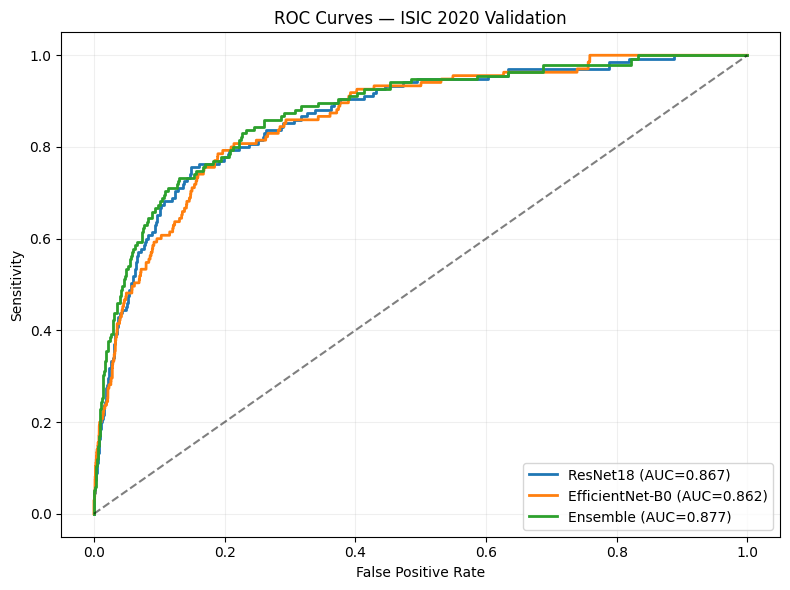

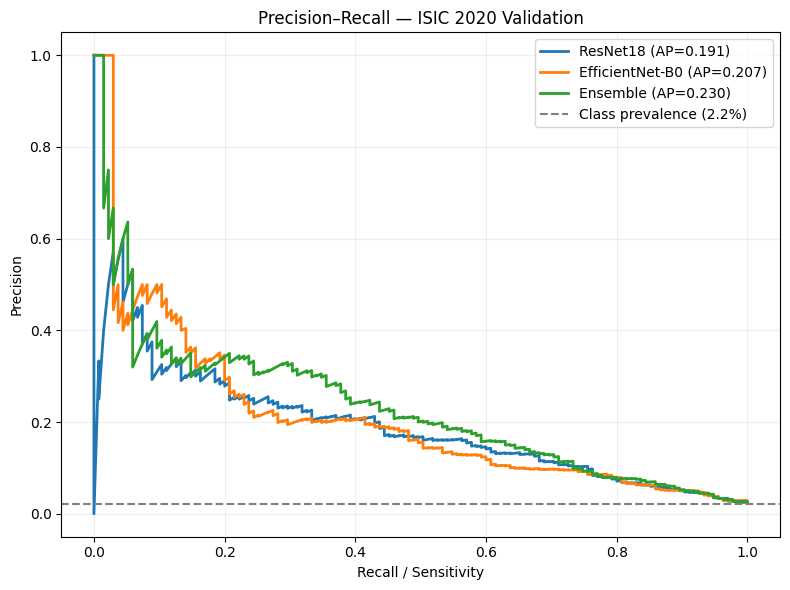

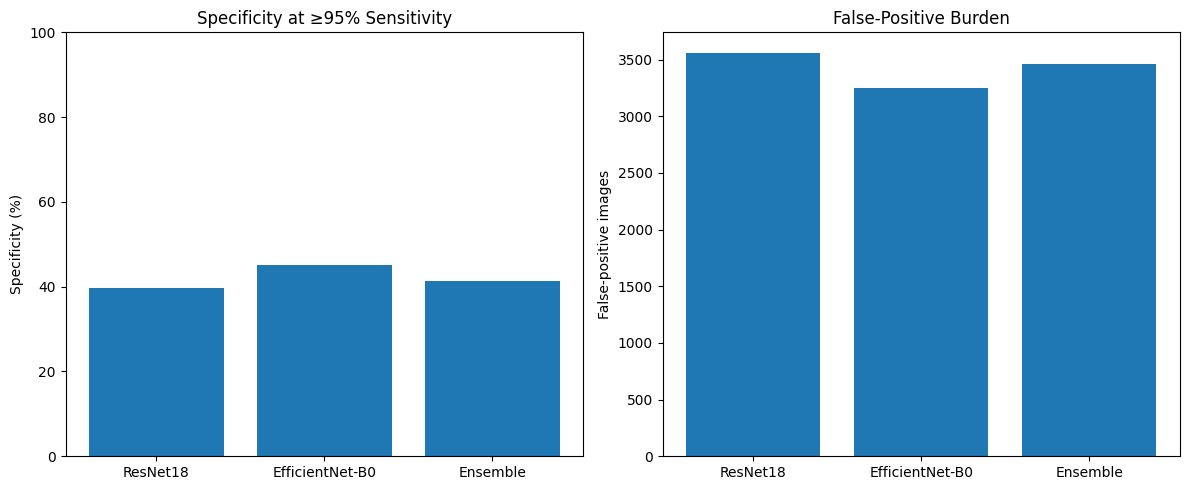

,Model,Sensitivity,Specificity,False positives,False negatives,Threshold
0,ResNet18,0.9556,0.3969,3563,6,0.0113
1,EfficientNet-B0,0.9556,0.4504,3247,6,0.0058
2,Ensemble,0.9556,0.4133,3466,6,0.0114


Poster graphs saved in: /kaggle/working/poster_figures


In [34]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

OUT = "/kaggle/working/poster_figures"
os.makedirs(OUT, exist_ok=True)

# Find saved predictions
paths = glob.glob(
    "/kaggle/working/**/ensemble_validation_predictions.csv",
    recursive=True
)

paths += glob.glob(
    "/kaggle/input/**/ensemble_validation_predictions.csv",
    recursive=True
)

if not paths:
    raise FileNotFoundError(
        "Attach the saved notebook output containing "
        "ensemble_validation_predictions.csv"
    )

df = pd.read_csv(paths[0])

y = df["actual_label_resnet"].to_numpy().astype(int)

models = {
    "ResNet18": df["model_score_resnet"].to_numpy(),
    "EfficientNet-B0": df["model_score_efficientnet"].to_numpy(),
    "Ensemble": df["ensemble_score"].to_numpy()
}

assert len(df) == 6043
assert y.sum() == 135
assert all(np.isfinite(s).all() for s in models.values())

# 1. ROC curves
plt.figure(figsize=(8, 6))

for name, scores in models.items():
    fpr, tpr, _ = roc_curve(y, scores)
    auc = roc_auc_score(y, scores)
    plt.plot(fpr, tpr, linewidth=2,
             label=f"{name} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("Sensitivity")
plt.title("ROC Curves — ISIC 2020 Validation")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(f"{OUT}/01_roc_curves.png", dpi=300)
plt.show()

# 2. Precision-recall curves
plt.figure(figsize=(8, 6))

for name, scores in models.items():
    precision, recall, _ = precision_recall_curve(y, scores)
    ap = average_precision_score(y, scores)
    plt.plot(recall, precision, linewidth=2,
             label=f"{name} (AP={ap:.3f})")

plt.axhline(
    y.mean(), linestyle="--", color="gray",
    label=f"Class prevalence ({y.mean():.1%})"
)

plt.xlabel("Recall / Sensitivity")
plt.ylabel("Precision")
plt.title("Precision–Recall — ISIC 2020 Validation")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(f"{OUT}/02_pr_curves.png", dpi=300)
plt.show()

# 3. Specificity at the same sensitivity target
# Recalculate using exact ROC thresholds, not rounded values.
rows = []

for name, scores in models.items():
    fpr, tpr, thresholds = roc_curve(y, scores)

    eligible = np.where(tpr >= 0.95)[0]
    idx = eligible[np.argmin(fpr[eligible])]
    threshold = thresholds[idx]

    pred = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y, pred, labels=[0, 1]
    ).ravel()

    rows.append({
        "Model": name,
        "Sensitivity": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "False positives": int(fp),
        "False negatives": int(fn),
        "Threshold": float(threshold)
    })

operating = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(
    operating["Model"],
    operating["Specificity"] * 100
)
axes[0].set_ylabel("Specificity (%)")
axes[0].set_title("Specificity at ≥95% Sensitivity")
axes[0].set_ylim(0, 100)

axes[1].bar(
    operating["Model"],
    operating["False positives"]
)
axes[1].set_ylabel("False-positive images")
axes[1].set_title("False-Positive Burden")

plt.tight_layout()
plt.savefig(f"{OUT}/03_high_sensitivity.png", dpi=300)
plt.show()

operating.to_csv(
    f"{OUT}/operating_point_metrics.csv",
    index=False
)

display(operating.round(4))
print("Poster graphs saved in:", OUT)

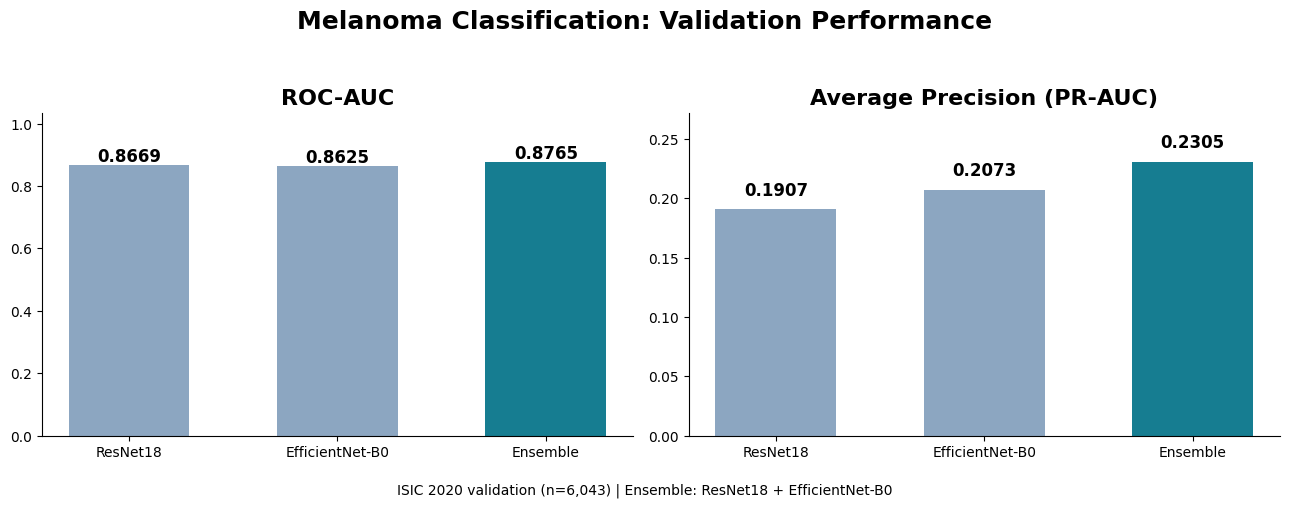

In [36]:
import matplotlib.pyplot as plt
import numpy as np
import os

os.makedirs("/kaggle/working/poster_figures", exist_ok=True)

models = ["ResNet18", "EfficientNet-B0", "Ensemble"]
roc_auc = [0.8669, 0.8625, 0.8765]
pr_auc = [0.1907, 0.2073, 0.2305]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

colors = ["#8CA6C1", "#8CA6C1", "#167D91"]

for ax, values, title in [
    (axes[0], roc_auc, "ROC-AUC"),
    (axes[1], pr_auc, "Average Precision (PR-AUC)")
]:
    bars = ax.bar(models, values, color=colors, width=0.58)

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            value + 0.012,
            f"{value:.4f}",
            ha="center",
            fontsize=12,
            fontweight="bold"
        )

    ax.set_ylim(0, max(values) * 1.18)
    ax.set_title(title, fontsize=16, fontweight="bold")
    ax.tick_params(axis="x", labelsize=10)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Melanoma Classification: Validation Performance",
    fontsize=18,
    fontweight="bold"
)

fig.text(
    0.5, 0.01,
    "ISIC 2020 validation (n=6,043) | "
    "Ensemble: ResNet18 + EfficientNet-B0",
    ha="center",
    fontsize=10
)

plt.tight_layout(rect=[0, 0.05, 1, 0.93])

plt.savefig(
    "/kaggle/working/poster_figures/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

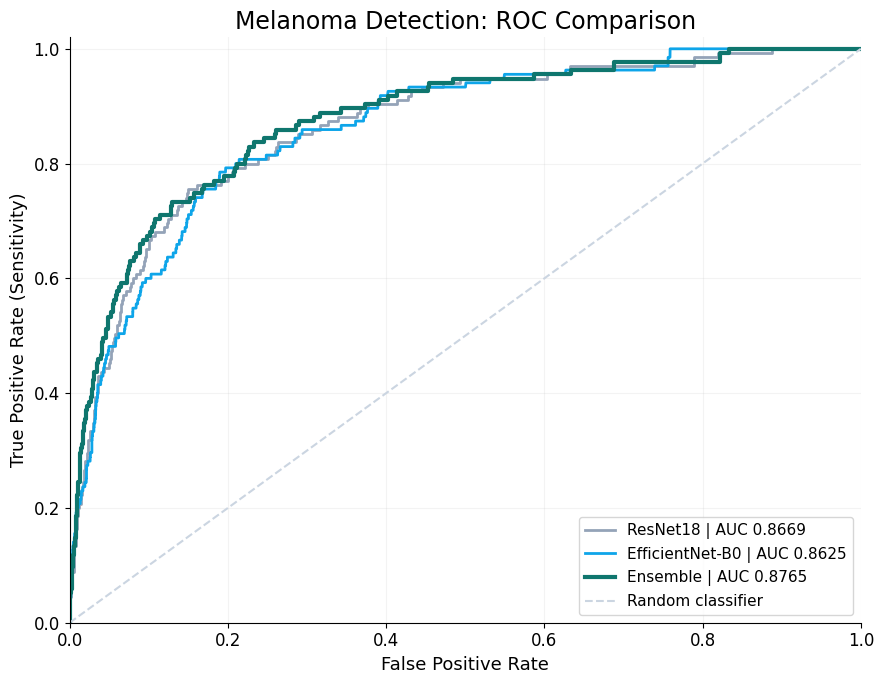

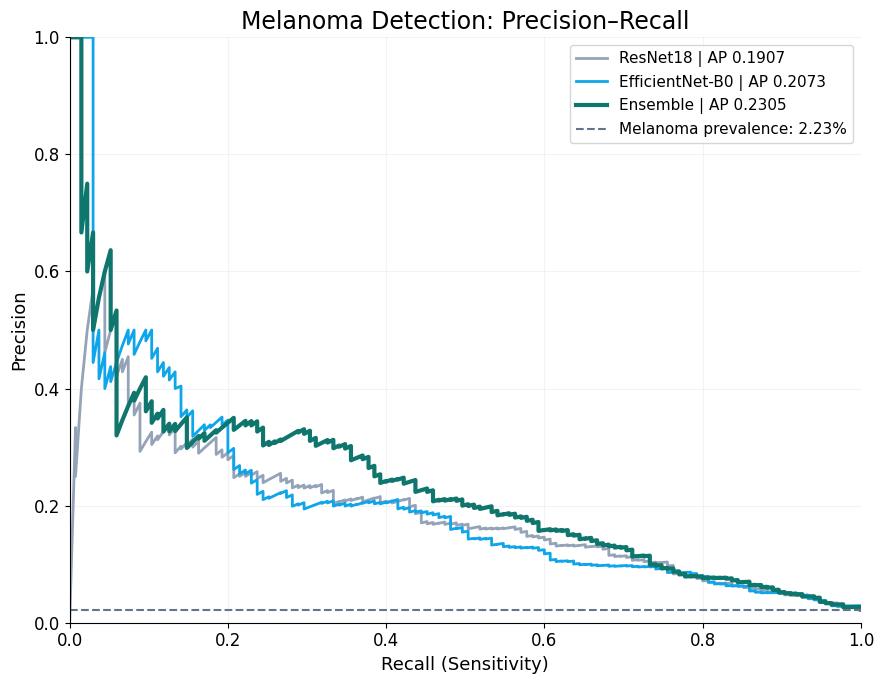

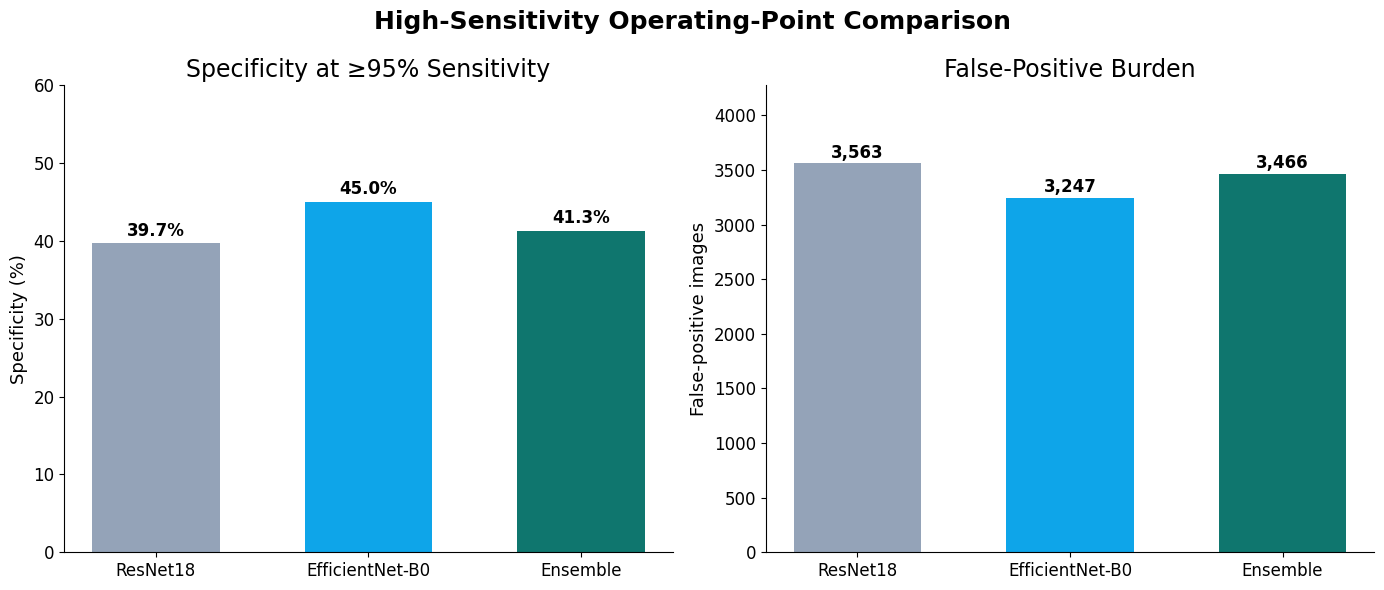

,Model,Sensitivity,Specificity,False Positives,False Negatives,Threshold
0,ResNet18,0.9556,0.3969,3563,6,0.0113
1,EfficientNet-B0,0.9556,0.4504,3247,6,0.0058
2,Ensemble,0.9556,0.4133,3466,6,0.0114


Poster-ready PNG and PDF figures saved: /kaggle/working/poster_figures


In [37]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

OUT = "/kaggle/working/poster_figures"
os.makedirs(OUT, exist_ok=True)

paths = (
    glob.glob(
        "/kaggle/working/**/ensemble_validation_predictions.csv",
        recursive=True
    )
    + glob.glob(
        "/kaggle/input/**/ensemble_validation_predictions.csv",
        recursive=True
    )
)

if not paths:
    raise FileNotFoundError(
        "Attach the saved ensemble validation predictions CSV."
    )

df = pd.read_csv(paths[0])

y = df["actual_label_resnet"].to_numpy(dtype=int)

models = {
    "ResNet18": df["model_score_resnet"].to_numpy(),
    "EfficientNet-B0": df["model_score_efficientnet"].to_numpy(),
    "Ensemble": df["ensemble_score"].to_numpy()
}

assert len(y) == 6043
assert y.sum() == 135

colors = {
    "ResNet18": "#94A3B8",
    "EfficientNet-B0": "#0EA5E9",
    "Ensemble": "#0F766E"
}

plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 17,
    "axes.labelsize": 13,
    "legend.fontsize": 11,
    "figure.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False
})

def save_figure(name):
    plt.savefig(
        f"{OUT}/{name}.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.savefig(
        f"{OUT}/{name}.pdf",
        bbox_inches="tight"
    )

# 1. ROC curves
plt.figure(figsize=(9, 7))

for name, scores in models.items():
    fpr, tpr, _ = roc_curve(y, scores)
    auc = roc_auc_score(y, scores)

    plt.plot(
        fpr, tpr,
        linewidth=3 if name == "Ensemble" else 2,
        color=colors[name],
        label=f"{name} | AUC {auc:.4f}"
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="#CBD5E1",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("Melanoma Detection: ROC Comparison")
plt.legend(loc="lower right")
plt.grid(alpha=0.15)
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.tight_layout()

save_figure("01_poster_roc")
plt.show()

# 2. Precision-recall curves
plt.figure(figsize=(9, 7))

for name, scores in models.items():
    precision, recall, _ = precision_recall_curve(
        y, scores
    )

    ap = average_precision_score(y, scores)

    plt.plot(
        recall, precision,
        linewidth=3 if name == "Ensemble" else 2,
        color=colors[name],
        label=f"{name} | AP {ap:.4f}"
    )

plt.axhline(
    y.mean(),
    linestyle="--",
    color="#64748B",
    label=f"Melanoma prevalence: {y.mean():.2%}"
)

plt.xlabel("Recall (Sensitivity)")
plt.ylabel("Precision")
plt.title("Melanoma Detection: Precision–Recall")
plt.legend()
plt.grid(alpha=0.15)
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.tight_layout()

save_figure("02_poster_precision_recall")
plt.show()

# 3. Operating-point analysis at >=95% sensitivity
rows = []

for name, scores in models.items():
    fpr, tpr, thresholds = roc_curve(y, scores)

    eligible = np.where(tpr >= 0.95)[0]
    best = eligible[np.argmin(fpr[eligible])]

    threshold = thresholds[best]
    pred = (scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y, pred, labels=[0, 1]
    ).ravel()

    rows.append({
        "Model": name,
        "Sensitivity": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "False Positives": fp,
        "False Negatives": fn,
        "Threshold": threshold
    })

results = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

bar_colors = [
    colors[name] for name in results["Model"]
]

bars = axes[0].bar(
    results["Model"],
    results["Specificity"] * 100,
    color=bar_colors,
    width=0.6
)

for bar, value in zip(
    bars, results["Specificity"] * 100
):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}%",
        ha="center",
        fontweight="bold"
    )

axes[0].set_ylim(0, 60)
axes[0].set_ylabel("Specificity (%)")
axes[0].set_title("Specificity at ≥95% Sensitivity")

bars = axes[1].bar(
    results["Model"],
    results["False Positives"],
    color=bar_colors,
    width=0.6
)

for bar, value in zip(
    bars, results["False Positives"]
):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 50,
        f"{value:,}",
        ha="center",
        fontweight="bold"
    )

axes[1].set_ylim(
    0, results["False Positives"].max() * 1.2
)
axes[1].set_ylabel("False-positive images")
axes[1].set_title("False-Positive Burden")

fig.suptitle(
    "High-Sensitivity Operating-Point Comparison",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
save_figure("03_poster_operating_point")
plt.show()

results.to_csv(
    f"{OUT}/operating_point_metrics.csv",
    index=False
)

display(results.round(4))

print("Poster-ready PNG and PDF figures saved:", OUT)

In [38]:
import os
import glob

model_names = [
    "best_resnet18.pth",
    "efficientnet_b0_best.pth"
]

for name in model_names:
    paths = (
        glob.glob(f"/kaggle/working/**/{name}", recursive=True)
        + glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    )

    print("\nMODEL:", name)

    if paths:
        for path in paths[:5]:
            size = os.path.getsize(path) / (1024 ** 2)
            print(f"FOUND: {path} ({size:.1f} MB)")
    else:
        print("NOT FOUND — attach the saved notebook outputs")


MODEL: best_resnet18.pth
FOUND: /kaggle/working/best_resnet18.pth (42.7 MB)
FOUND: /kaggle/input/notebooks/mahjabinhossain/notebooka2fd61ea28/best_resnet18.pth (42.7 MB)

MODEL: efficientnet_b0_best.pth
FOUND: /kaggle/working/efficientnet_b0_best.pth (15.6 MB)
FOUND: /kaggle/input/notebooks/mahjabinhossain/notebooka2fd61ea28/efficientnet_b0_best.pth (15.6 MB)


In [47]:
import os
import numpy as np
import pandas as pd

ROOT = (
    "/kaggle/input/datasets/nazmusresan/"
    "fitzpatrick17k/New folder"
)

IMAGE_DIR = os.path.join(ROOT, "background removed")

fitz_df = pd.read_csv(
    os.path.join(ROOT, "fitzpatrick17k (1).csv")
)

fitz_df["image_path"] = (
    IMAGE_DIR + "/" +
    fitz_df["md5hash"].astype(str) + ".jpg"
)

melanoma_labels = {
    "melanoma",
    "malignant melanoma",
    "superficial spreading melanoma ssm"
}

# Exact diagnosis matching avoids accidental substring matches
is_melanoma = (
    fitz_df["label"]
    .astype(str)
    .str.lower()
    .str.strip()
    .isin(melanoma_labels)
)

is_benign = (
    fitz_df["three_partition_label"]
    .astype(str)
    .str.lower()
    .eq("benign")
)

# Only clinically meaningful recorded FST categories
valid_skin_type = fitz_df["fitzpatrick_scale"].isin(
    [1, 2, 3, 4, 5, 6]
)

fairness_df = fitz_df[
    (is_melanoma | is_benign)
    & valid_skin_type
].copy()

fairness_df = fairness_df[
    fairness_df["image_path"].map(os.path.isfile)
].copy()

fairness_df["target"] = (
    fairness_df["label"]
    .astype(str)
    .str.lower()
    .str.strip()
    .isin(melanoma_labels)
    .astype(int)
)

def get_skin_group(fst):
    fst = int(fst)

    if fst <= 2:
        return "I-II"
    elif fst <= 4:
        return "III-IV"
    else:
        return "V-VI"

fairness_df["skin_group"] = (
    fairness_df["fitzpatrick_scale"]
    .apply(get_skin_group)
)

fairness_df = fairness_df.reset_index(drop=True)

print("===== FAIRNESS EVALUATION DATASET =====")
print("Total images:", len(fairness_df))

print("\nMelanoma vs benign by skin group:")
summary = pd.crosstab(
    fairness_df["skin_group"],
    fairness_df["target"]
).reindex(["I-II", "III-IV", "V-VI"], fill_value=0)

summary.columns = ["Benign", "Melanoma"]
display(summary)

print("\nImage paths verified:", fairness_df["image_path"].map(os.path.isfile).all())
print("Unique images:", fairness_df["md5hash"].nunique())

OUTPUT = "/kaggle/working/fitzpatrick_melanoma_fairness_cohort.csv"
fairness_df.to_csv(OUTPUT, index=False)

print("\nSaved:", OUTPUT)

===== FAIRNESS EVALUATION DATASET =====
Total images: 2625

Melanoma vs benign by skin group:


,Benign,Melanoma
skin_group,,
I-II,1115,290
III-IV,842,132
V-VI,203,43



Image paths verified: True
Unique images: 2625

Saved: /kaggle/working/fitzpatrick_melanoma_fairness_cohort.csv


In [64]:
import torch
import numpy as np
import glob

CHECKPOINT_NAMES = {
    "ResNet18": "best_resnet18.pth",
    "EfficientNet-B0": "efficientnet_b0_best.pth"
}

checkpoint_paths = {}

for name, filename in CHECKPOINT_NAMES.items():
    matches = (
        glob.glob(f"/kaggle/working/**/{filename}", recursive=True)
        + glob.glob(f"/kaggle/input/**/{filename}", recursive=True)
    )

    print(f"\n===== {name} =====")

    if not matches:
        print("NOT FOUND")
        continue

    path = matches[0]

    try:
        with torch.serialization.safe_globals([
            np._core.multiarray.scalar,
            np.dtype,
            type(np.dtype(np.float64))
        ]):
            ckpt = torch.load(
                path,
                map_location="cpu",
                weights_only=True
            )

        state = ckpt.get("model_state_dict", ckpt)

        checkpoint_paths[name] = path

        print("Loaded successfully")
        print("Path:", path)
        print("Epoch:", ckpt.get("epoch", "Unknown"))
        print("Image size:", ckpt.get("image_size", "Unknown"))
        print("Validation PR-AUC:",
              ckpt.get("validation_pr_auc", "Unknown"))

        classifier_keys = [
            k for k in state
            if k.endswith(("fc.weight", "classifier.1.weight"))
        ]

        for key in classifier_keys:
            print("Classifier:", key, tuple(state[key].shape))

    except Exception as e:
        print("Loading failed:", str(e)[:400])

print("\nModels ready:", len(checkpoint_paths), "/ 2")


===== ResNet18 =====
Loaded successfully
Path: /kaggle/working/best_resnet18.pth
Epoch: 6
Image size: 224
Validation PR-AUC: 0.1906621395502733
Classifier: fc.weight (1, 512)

===== EfficientNet-B0 =====
Loaded successfully
Path: /kaggle/working/efficientnet_b0_best.pth
Epoch: 3
Image size: Unknown
Validation PR-AUC: 0.20728081952958788
Classifier: classifier.1.weight (1, 1280)

Models ready: 2 / 2


In [89]:

import pandas as pd
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

df = pd.read_csv(
    "/kaggle/working/detailed_model_comparison.csv"
)

assert (
    df["actual_label_resnet"]
    == df["actual_label_efficientnet"]
).all(), "Model labels do not match!"

y_true = df["actual_label_resnet"].astype(int)

models = {
    "ResNet18": "model_score_resnet",
    "EfficientNet-B0": "model_score_efficientnet",
    "Ensemble": "ensemble_score"
}

results = []

for name, column in models.items():
    probabilities = df[column]
    predictions = (probabilities >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    results.append({
        "Model": name,
        "PR-AUC": average_precision_score(
            y_true, probabilities
        ),
        "ROC-AUC": roc_auc_score(
            y_true, probabilities
        ),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions, zero_division=0
        ),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))


,Model,PR-AUC,ROC-AUC,Precision,Recall,F1,TP,FP,FN,TN
0,ResNet18,0.1907,0.8669,0.2053,0.4000,0.2714,54,209,81,5699
1,EfficientNet-B0,0.2073,0.8625,0.2254,0.2370,0.2310,32,110,103,5798
2,Ensemble,0.2305,0.8765,0.3061,0.3333,0.3191,45,102,90,5806


In [90]:

import pandas as pd
import numpy as np
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    confusion_matrix
)

df = pd.read_csv(
    "/kaggle/working/detailed_model_comparison.csv"
)

y = df["actual_label_resnet"].astype(int).values

scores = {
    "ResNet18": df["model_score_resnet"].values,
    "EfficientNet-B0": df["model_score_efficientnet"].values,
    "Ensemble": df["ensemble_score"].values
}

thresholds = [0.05, 0.10, 0.20, 0.30, 0.40, 0.50]

rows = []

for model_name, probabilities in scores.items():
    for threshold in thresholds:
        pred = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y, pred, labels=[0, 1]
        ).ravel()

        rows.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision_score(
                y, pred, zero_division=0
            ),
            "Recall": recall_score(
                y, pred, zero_division=0
            ),
            "F1": f1_score(
                y, pred, zero_division=0
            ),
            "TP": tp,
            "FP": fp,
            "FN": fn
        })

threshold_results = pd.DataFrame(rows)

display(threshold_results.round(4))


,Model,Threshold,Precision,Recall,F1,TP,FP,FN
0,ResNet18,0.05,0.0449,0.9333,0.0856,126,2682,9
1,ResNet18,0.10,0.0537,0.8815,0.1013,119,2095,16
2,ResNet18,0.20,0.0801,0.7852,0.1454,106,1217,29
3,ResNet18,0.30,0.1238,0.6815,0.2096,92,651,43
4,ResNet18,0.40,0.1615,0.5037,0.2446,68,353,67
5,ResNet18,0.50,0.2053,0.4000,0.2714,54,209,81
6,EfficientNet-B0,0.05,0.0624,0.8593,0.1163,116,1743,19
7,EfficientNet-B0,0.10,0.0803,0.7926,0.1459,107,1225,28
8,EfficientNet-B0,0.20,0.1053,0.6370,0.1807,86,731,49
9,EfficientNet-B0,0.30,0.1437,0.5333,0.2264,72,429,63


In [97]:

import torch
import numpy as np
import pandas as pd

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Use only if these match the original training transforms
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class FitzpatrickDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        with Image.open(row["image_path"]) as img:
            image = img.convert("RGB")

        image = self.transform(image)

        return (
            image,
            int(row["target"]),
            str(row["md5hash"])
        )

fitz_dataset = FitzpatrickDataset(
    eval_df,
    eval_transform
)

fitz_loader = DataLoader(
    fitz_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

images, labels, image_ids = next(iter(fitz_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Example ID:", image_ids[0])
print("Total batches:", len(fitz_loader))


Images: torch.Size([32, 3, 224, 224])
Labels: torch.Size([32])
Example ID: d2bac3c9e4499032ca8e9b07c7d3bc40
Total batches: 83


In [98]:

@torch.inference_mode()
def predict_fitz(model, loader):
    model = model.to(device)
    model.eval()

    probabilities = []
    image_ids = []

    for images, _, ids in loader:
        images = images.to(device)

        logits = model(images).view(-1)
        probs = torch.sigmoid(logits)

        probabilities.extend(probs.cpu().tolist())
        image_ids.extend(ids)

    return pd.DataFrame({
        "md5hash": image_ids,
        "score": probabilities
    })

resnet_pred = predict_fitz(resnet18_model, fitz_loader)
resnet_pred = resnet_pred.rename(
    columns={"score": "resnet_score"}
)

efficientnet_pred = predict_fitz(
    efficientnet_model,
    fitz_loader
)
efficientnet_pred = efficientnet_pred.rename(
    columns={"score": "efficientnet_score"}
)

results = eval_df.merge(
    resnet_pred,
    on="md5hash",
    how="left",
    validate="one_to_one"
).merge(
    efficientnet_pred,
    on="md5hash",
    how="left",
    validate="one_to_one"
)

# Match the earlier 50/50 ensemble
results["ensemble_score"] = (
    results["resnet_score"]
    + results["efficientnet_score"]
) / 2

assert results[
    ["resnet_score", "efficientnet_score", "ensemble_score"]
].notna().all().all()

results.to_csv(
    "/kaggle/working/fitzpatrick_model_predictions.csv",
    index=False
)

print("Predictions completed:", len(results))
display(results[
    ["skin_group", "target", "resnet_score",
     "efficientnet_score", "ensemble_score"]
].head())


Predictions completed: 2625


,skin_group,target,resnet_score,efficientnet_score,ensemble_score
0,I-II,0,0.122422,0.372197,0.247310
1,I-II,1,0.366238,0.135935,0.251087
2,V-VI,1,0.154923,0.304819,0.229871
3,I-II,0,0.068161,0.037278,0.052720
4,I-II,0,0.152441,0.339199,0.245820


In [99]:

import torch
import numpy as np
import pandas as pd

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Use only if these match the original training transforms
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class FitzpatrickDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        with Image.open(row["image_path"]) as img:
            image = img.convert("RGB")

        image = self.transform(image)

        return (
            image,
            int(row["target"]),
            str(row["md5hash"])
        )

fitz_dataset = FitzpatrickDataset(
    eval_df,
    eval_transform
)

fitz_loader = DataLoader(
    fitz_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

images, labels, image_ids = next(iter(fitz_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Example ID:", image_ids[0])
print("Total batches:", len(fitz_loader))


Images: torch.Size([32, 3, 224, 224])
Labels: torch.Size([32])
Example ID: d2bac3c9e4499032ca8e9b07c7d3bc40
Total batches: 83


In [100]:

import pandas as pd
import numpy as np

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

results = pd.read_csv(
    "/kaggle/working/fitzpatrick_model_predictions.csv"
)

models = {
    "ResNet18": ("resnet_score", 0.0871),
    "EfficientNet-B0": ("efficientnet_score", 0.0222),
    "Ensemble": ("ensemble_score", 0.0656)
}

rows = []

for group in ["I-II", "III-IV", "V-VI"]:
    subset = results[
        results["skin_group"] == group
    ]

    y_true = subset["target"].astype(int).values

    for model_name, (column, threshold) in models.items():

        y_score = subset[column].values
        y_pred = (y_score >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true, y_pred, labels=[0, 1]
        ).ravel()

        rows.append({
            "Skin Group": group,
            "Model": model_name,
            "Images": len(subset),
            "Melanoma": int(y_true.sum()),
            "PR-AUC": average_precision_score(
                y_true, y_score
            ),
            "ROC-AUC": roc_auc_score(
                y_true, y_score
            ) if len(np.unique(y_true)) == 2 else np.nan,
            "Precision": precision_score(
                y_true, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_true, y_pred, zero_division=0
            ),
            "Specificity": (
                tn / (tn + fp)
                if (tn + fp) else np.nan
            ),
            "F1": f1_score(
                y_true, y_pred, zero_division=0
            ),
            "TP": int(tp),
            "FP": int(fp),
            "FN": int(fn),
            "TN": int(tn)
        })

fairness_df = pd.DataFrame(rows)

display(fairness_df.round(4))

fairness_df.to_csv(
    "/kaggle/working/fitzpatrick_fairness_results.csv",
    index=False
)


,Skin Group,Model,Images,Melanoma,PR-AUC,ROC-AUC,Precision,Recall,Specificity,F1,TP,FP,FN,TN
0,I-II,ResNet18,1405,290,0.2351,0.5620,0.2125,0.9517,0.0825,0.3474,276,1023,14,92
1,I-II,EfficientNet-B0,1405,290,0.2461,0.5760,0.2153,0.9586,0.0915,0.3517,278,1013,12,102
2,I-II,Ensemble,1405,290,0.2549,0.5771,0.2118,0.9552,0.0753,0.3467,277,1031,13,84
3,III-IV,ResNet18,974,132,0.1752,0.5992,0.1442,0.9015,0.1615,0.2487,119,706,13,136
4,III-IV,EfficientNet-B0,974,132,0.1529,0.5302,0.1408,0.8864,0.1520,0.2430,117,714,15,128
5,III-IV,Ensemble,974,132,0.1737,0.5796,0.1395,0.9015,0.1283,0.2416,119,734,13,108
6,V-VI,ResNet18,246,43,0.2982,0.6286,0.1822,0.9535,0.0936,0.3060,41,184,2,19
7,V-VI,EfficientNet-B0,246,43,0.1810,0.4838,0.1732,0.9302,0.0591,0.2920,40,191,3,12
8,V-VI,Ensemble,246,43,0.2419,0.5846,0.1818,0.9767,0.0690,0.3066,42,189,1,14


Model,EfficientNet-B0,Ensemble,ResNet18
Skin Group,,,
I-II,0.9586,0.9552,0.9517
III-IV,0.8864,0.9015,0.9015
V-VI,0.9302,0.9767,0.9535


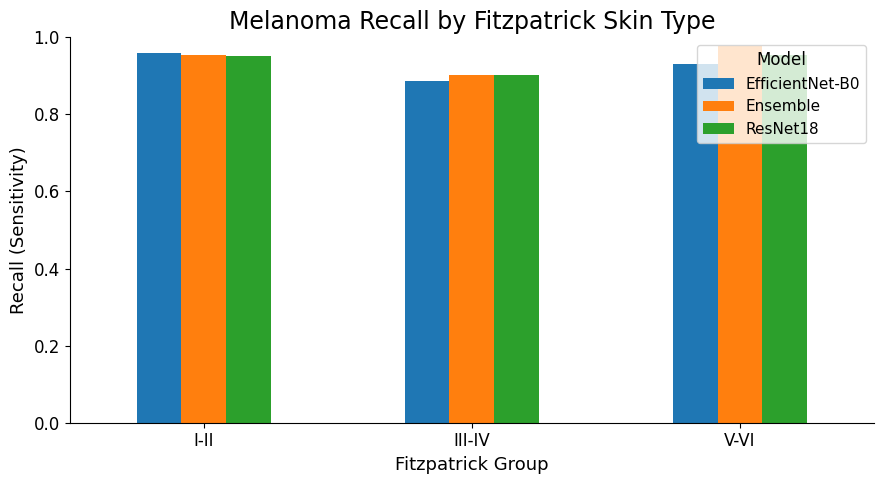

In [101]:

import matplotlib.pyplot as plt

recall_table = fairness_df.pivot(
    index="Skin Group",
    columns="Model",
    values="Recall"
)

display(recall_table.round(4))

ax = recall_table.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title("Melanoma Recall by Fitzpatrick Skin Type")
ax.set_ylabel("Recall (Sensitivity)")
ax.set_xlabel("Fitzpatrick Group")
ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()


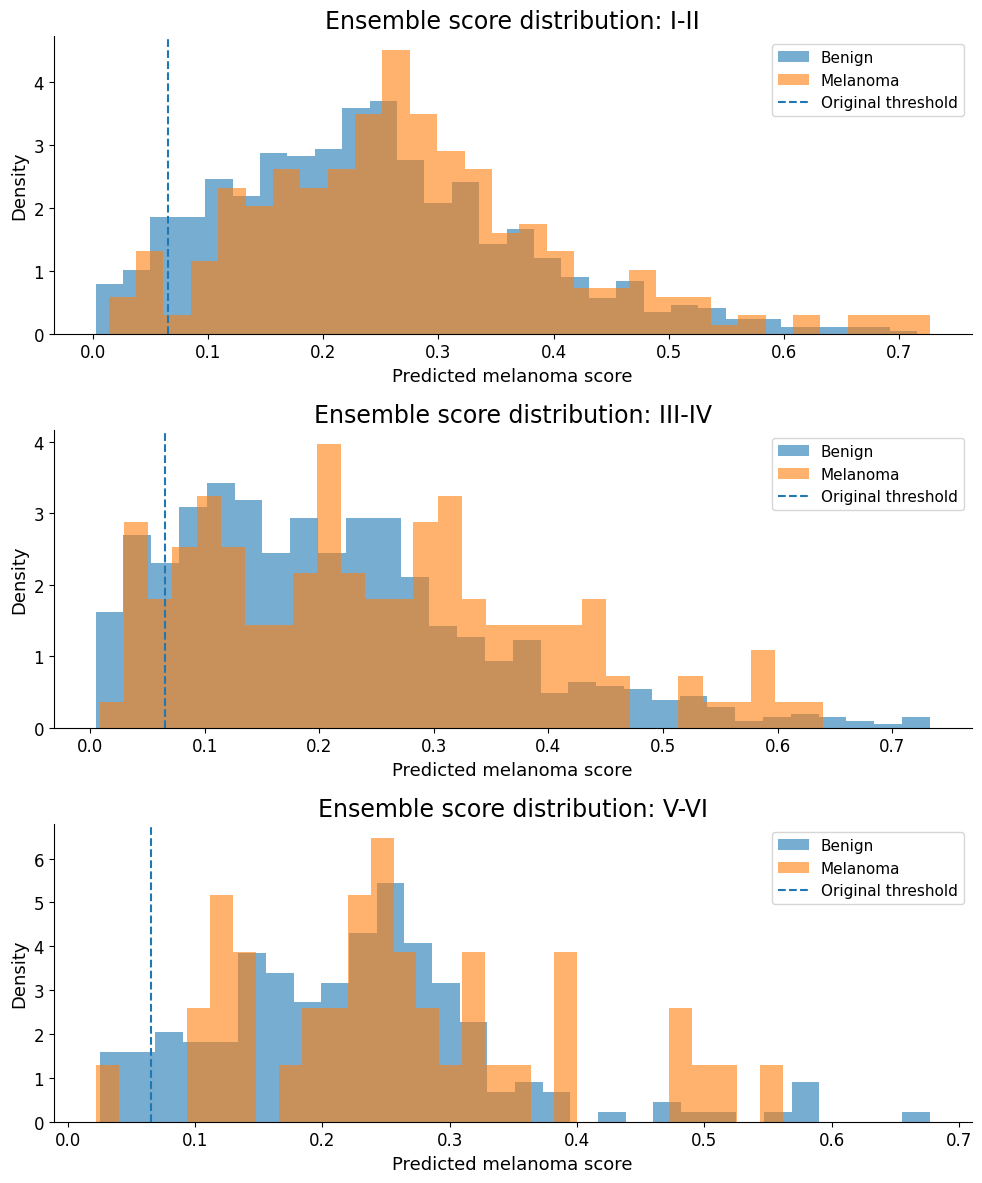

In [103]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    "/kaggle/working/fitzpatrick_model_predictions.csv"
)

fig, axes = plt.subplots(3, 1, figsize=(10, 12))

for ax, group in zip(axes, ["I-II", "III-IV", "V-VI"]):
    subset = df[df["skin_group"] == group]

    benign = subset[subset["target"] == 0]["ensemble_score"]
    melanoma = subset[subset["target"] == 1]["ensemble_score"]

    ax.hist(
        benign, bins=30, alpha=0.6,
        density=True, label="Benign"
    )
    ax.hist(
        melanoma, bins=30, alpha=0.6,
        density=True, label="Melanoma"
    )

    ax.axvline(
        0.0656, linestyle="--",
        label="Original threshold"
    )

    ax.set_title(f"Ensemble score distribution: {group}")
    ax.set_xlabel("Predicted melanoma score")
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()


In [1]:

import os

files = [
    "/kaggle/working/best_resnet18.pth",
    "/kaggle/working/efficientnet_b0_best.pth",
    "/kaggle/working/fitzpatrick_melanoma_evaluation.csv",
    "/kaggle/working/fitzpatrick_model_predictions.csv",
    "/kaggle/working/fitzpatrick_fairness_results.csv",
    "/kaggle/working/fitzpatrick_confidence_intervals.csv"
]

for path in files:
    status = "FOUND" if os.path.exists(path) else "MISSING"
    print(f"{status}: {os.path.basename(path)}")


FOUND: best_resnet18.pth
FOUND: efficientnet_b0_best.pth
FOUND: fitzpatrick_melanoma_evaluation.csv
FOUND: fitzpatrick_model_predictions.csv
FOUND: fitzpatrick_fairness_results.csv
FOUND: fitzpatrick_confidence_intervals.csv


In [2]:

import pandas as pd

df = pd.read_csv(
    "/kaggle/working/fitzpatrick_model_predictions.csv"
)

summary = (
    df.groupby(["skin_group", "target"])["ensemble_score"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .reset_index()
)

summary["Diagnosis"] = summary["target"].map({
    0: "Benign",
    1: "Melanoma"
})

display(
    summary[
        ["skin_group", "Diagnosis", "count",
         "mean", "median", "std", "min", "max"]
    ].round(4)
)


,skin_group,Diagnosis,count,mean,median,std,min,max
0,I-II,Benign,1115,0.2413,0.2294,0.1295,0.0024,0.7160
1,I-II,Melanoma,290,0.2747,0.2632,0.1317,0.0138,0.7267
2,III-IV,Benign,842,0.2118,0.1923,0.1393,0.0046,0.7330
3,III-IV,Melanoma,132,0.2496,0.2300,0.1471,0.0086,0.6398
4,V-VI,Benign,203,0.2251,0.2249,0.1121,0.0253,0.6771
5,V-VI,Melanoma,43,0.2625,0.2473,0.1250,0.0218,0.5620


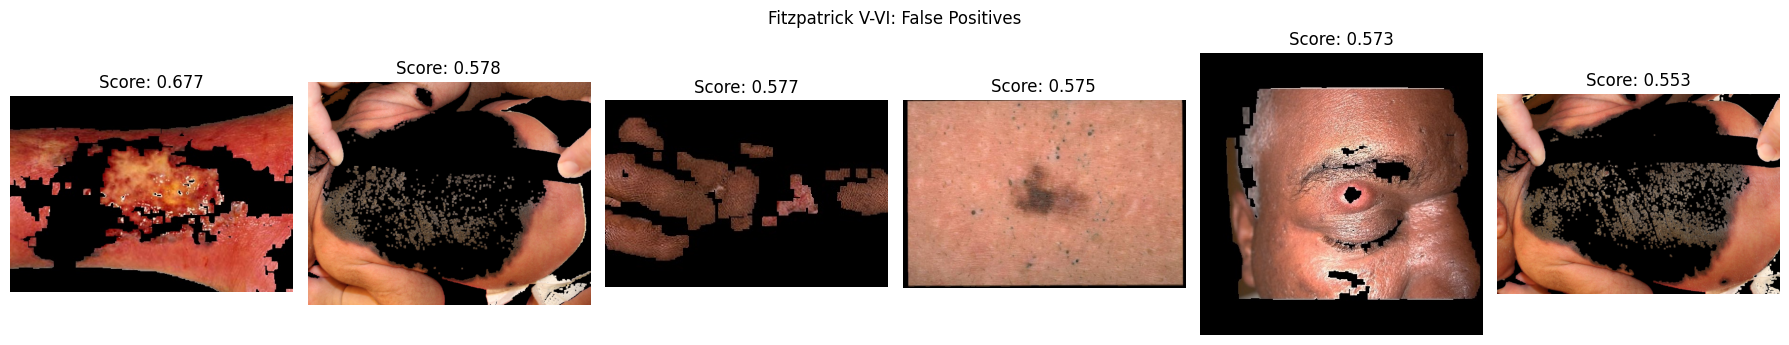

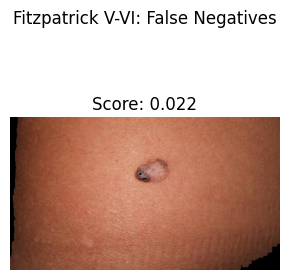

In [3]:

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

df = pd.read_csv(
    "/kaggle/working/fitzpatrick_model_predictions.csv"
)

threshold = 0.0656

dark = df[df["skin_group"] == "V-VI"].copy()
dark["predicted"] = (
    dark["ensemble_score"] >= threshold
).astype(int)

# High-scoring benign images
false_positives = (
    dark[(dark["target"] == 0) & (dark["predicted"] == 1)]
    .sort_values("ensemble_score", ascending=False)
    .head(6)
)

# Missed melanoma images
false_negatives = (
    dark[(dark["target"] == 1) & (dark["predicted"] == 0)]
    .sort_values("ensemble_score")
    .head(6)
)

def show_cases(cases, title):
    if len(cases) == 0:
        print(title, ": No examples")
        return

    fig, axes = plt.subplots(
        1, len(cases),
        figsize=(3 * len(cases), 3.5),
        squeeze=False
    )

    for ax, (_, row) in zip(axes[0], cases.iterrows()):
        with Image.open(row["image_path"]) as im:
            ax.imshow(im.convert("RGB"))

        ax.set_title(
            f"Score: {row['ensemble_score']:.3f}"
        )
        ax.axis("off")

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_cases(
    false_positives,
    "Fitzpatrick V-VI: False Positives"
)

show_cases(
    false_negatives,
    "Fitzpatrick V-VI: False Negatives"
)


In [4]:

import pandas as pd
import numpy as np
from PIL import Image
from tqdm.auto import tqdm

df = pd.read_csv(
    "/kaggle/working/fitzpatrick_model_predictions.csv"
)

def black_pixel_ratio(image_path):
    with Image.open(image_path) as img:
        img = img.convert("RGB")
        img.thumbnail((256, 256))
        arr = np.asarray(img)

    # Pixels near black in all RGB channels
    black_mask = np.all(arr < 20, axis=2)
    return float(black_mask.mean())

tqdm.pandas()

df["black_pixel_ratio"] = df["image_path"].progress_apply(
    black_pixel_ratio
)

df["predicted"] = (
    df["ensemble_score"] >= 0.0656
).astype(int)

df["error_type"] = np.select(
    [
        (df["target"] == 0) & (df["predicted"] == 1),
        (df["target"] == 1) & (df["predicted"] == 0)
    ],
    ["False Positive", "False Negative"],
    default="Correct"
)

summary = (
    df.groupby(["skin_group", "error_type"])
      ["black_pixel_ratio"]
      .agg(["count", "mean", "median"])
      .reset_index()
)

display(summary.round(4))

df.to_csv(
    "/kaggle/working/fitzpatrick_artifact_analysis.csv",
    index=False
)


  0%|          | 0/2625 [00:00<?, ?it/s]

,skin_group,error_type,count,mean,median
0,I-II,Correct,361,0.2991,0.2050
1,I-II,False Negative,13,0.0948,0.0551
2,I-II,False Positive,1031,0.3760,0.2854
3,III-IV,Correct,227,0.1678,0.0519
4,III-IV,False Negative,13,0.0507,0.0172
5,III-IV,False Positive,734,0.2800,0.1930
6,V-VI,Correct,56,0.3797,0.3741
7,V-VI,False Negative,1,0.0261,0.0261
8,V-VI,False Positive,189,0.4540,0.4281


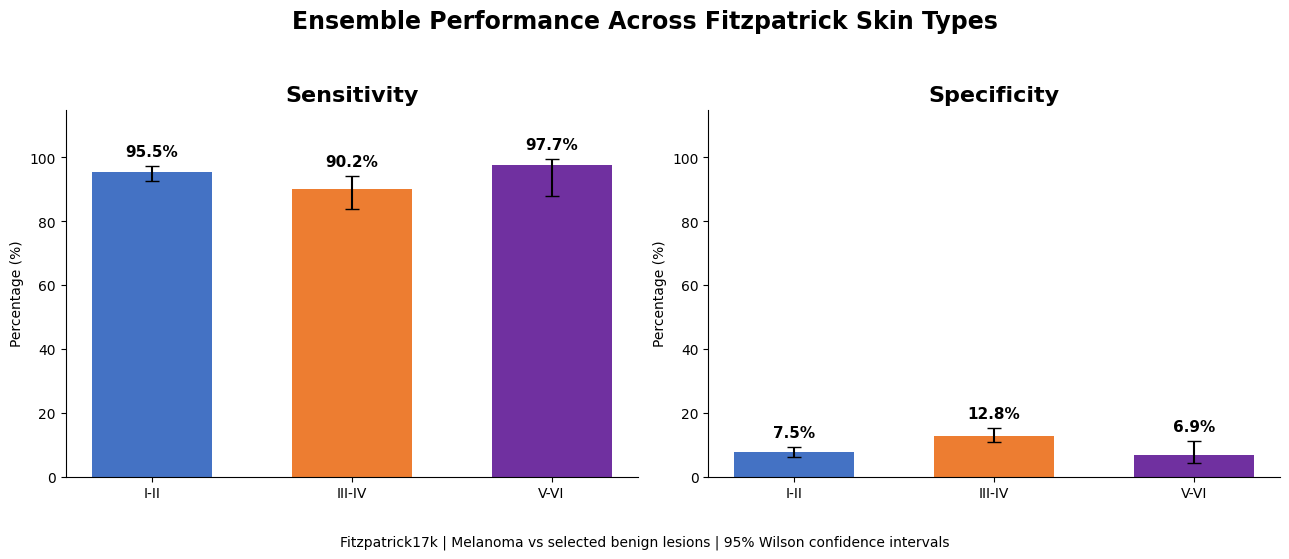

,Group,TP,FN,TN,FP,Sensitivity,Specificity,Sensitivity_low,Sensitivity_high,Specificity_low,Specificity_high
0,I-II,277,13,84,1031,0.9552,0.0753,0.9248,0.9736,0.0613,0.0923
1,III-IV,119,13,108,734,0.9015,0.1283,0.8388,0.9415,0.1074,0.1526
2,V-VI,42,1,14,189,0.9767,0.0690,0.8794,0.9959,0.0415,0.1124


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportion_confint

OUT = "/kaggle/working/poster_figures"
os.makedirs(OUT, exist_ok=True)

results = pd.DataFrame({
    "Group": ["I-II", "III-IV", "V-VI"],
    "TP": [277, 119, 42],
    "FN": [13, 13, 1],
    "TN": [84, 108, 14],
    "FP": [1031, 734, 189]
})

results["Sensitivity"] = results.TP / (results.TP + results.FN)
results["Specificity"] = results.TN / (results.TN + results.FP)

colors = ["#4472C4", "#ED7D31", "#7030A0"]

# 95% Wilson confidence intervals
for metric, success, total in [
    ("Sensitivity", results.TP, results.TP + results.FN),
    ("Specificity", results.TN, results.TN + results.FP)
]:
    low, high = proportion_confint(
        success, total, alpha=0.05, method="wilson"
    )
    results[f"{metric}_low"] = low
    results[f"{metric}_high"] = high

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, metric in zip(
    axes, ["Sensitivity", "Specificity"]
):
    values = results[metric].to_numpy() * 100
    lower = results[f"{metric}_low"].to_numpy() * 100
    upper = results[f"{metric}_high"].to_numpy() * 100

    yerr = np.vstack([
        values - lower,
        upper - values
    ])

    ax.bar(
        results["Group"],
        values,
        color=colors,
        width=0.6
    )

    ax.errorbar(
        range(3), values,
        yerr=yerr,
        fmt="none",
        ecolor="black",
        capsize=5
    )

    for i, value in enumerate(values):
        ax.text(
            i, min(103, upper[i] + 3),
            f"{value:.1f}%",
            ha="center",
            fontweight="bold",
            fontsize=11
        )

    ax.set_ylim(0, 115)
    ax.set_ylabel("Percentage (%)")
    ax.set_title(metric, fontsize=16, fontweight="bold")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Ensemble Performance Across Fitzpatrick Skin Types",
    fontsize=17,
    fontweight="bold"
)

fig.text(
    0.5, 0.005,
    "Fitzpatrick17k | Melanoma vs selected benign lesions | "
    "95% Wilson confidence intervals",
    ha="center",
    fontsize=10
)

plt.tight_layout(rect=[0, 0.06, 1, 0.94])

plt.savefig(
    f"{OUT}/04_skin_tone_performance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    f"{OUT}/04_skin_tone_performance.pdf",
    bbox_inches="tight"
)

plt.show()

results.to_csv(
    f"{OUT}/skin_tone_metrics.csv",
    index=False
)

display(results.round(4))

In [2]:
import glob
import pandas as pd

for path in glob.glob("/kaggle/working/**/*.csv", recursive=True):
    try:
        d = pd.read_csv(path, nrows=2)
        cols = d.columns.tolist()

        if any("score" in c.lower() or "prob" in c.lower()
               for c in cols):
            print("\nFILE:", path)
            print("COLUMNS:", cols)
    except Exception:
        pass


FILE: /kaggle/working/ensemble_validation_predictions.csv
COLUMNS: ['image_name', 'patient_id_resnet', 'actual_label_resnet', 'model_score_resnet', 'patient_id_efficientnet', 'actual_label_efficientnet', 'model_score_efficientnet', 'ensemble_score']

FILE: /kaggle/working/fitzpatrick_model_predictions.csv
COLUMNS: ['md5hash', 'fitzpatrick_scale', 'fitzpatrick_centaur', 'label', 'nine_partition_label', 'three_partition_label', 'qc', 'url', 'url_alphanum', 'diagnosis', 'category', 'image_path', 'target', 'skin_group', 'resnet_score', 'efficientnet_score', 'ensemble_score']

FILE: /kaggle/working/resnet18_validation_predictions.csv
COLUMNS: ['image_name', 'patient_id', 'actual_label', 'model_score']

FILE: /kaggle/working/efficientnet_b0_validation_predictions.csv
COLUMNS: ['image_name', 'patient_id', 'actual_label', 'model_score']

FILE: /kaggle/working/detailed_model_comparison.csv
COLUMNS: ['image_name', 'patient_id_resnet', 'actual_label_resnet', 'model_score_resnet', 'patient_id_eff

===== EXTERNAL MODEL PERFORMANCE =====
ResNet18           ROC-AUC=0.5865  PR-AUC=0.2151
EfficientNet-B0    ROC-AUC=0.5623  PR-AUC=0.2062
Ensemble           ROC-AUC=0.5873  PR-AUC=0.2216

===== EXPLORATORY THRESHOLD COMPARISON =====


,Model,Target Sensitivity,Threshold,Sensitivity,Specificity,False Positives,False Negatives
0,ResNet18,95%,0.0728,0.9505,0.0907,1964,23
1,ResNet18,90%,0.1154,0.9011,0.1713,1790,46
2,ResNet18,85%,0.1330,0.8516,0.2366,1649,69
3,EfficientNet-B0,95%,0.0156,0.9527,0.0801,1987,22
4,EfficientNet-B0,90%,0.0306,0.9011,0.1407,1856,46
5,EfficientNet-B0,85%,0.0537,0.8516,0.2144,1697,69
6,Ensemble,95%,0.0590,0.9505,0.0801,1987,23
7,Ensemble,90%,0.1031,0.9011,0.1810,1769,46
8,Ensemble,85%,0.1225,0.8516,0.2361,1650,69


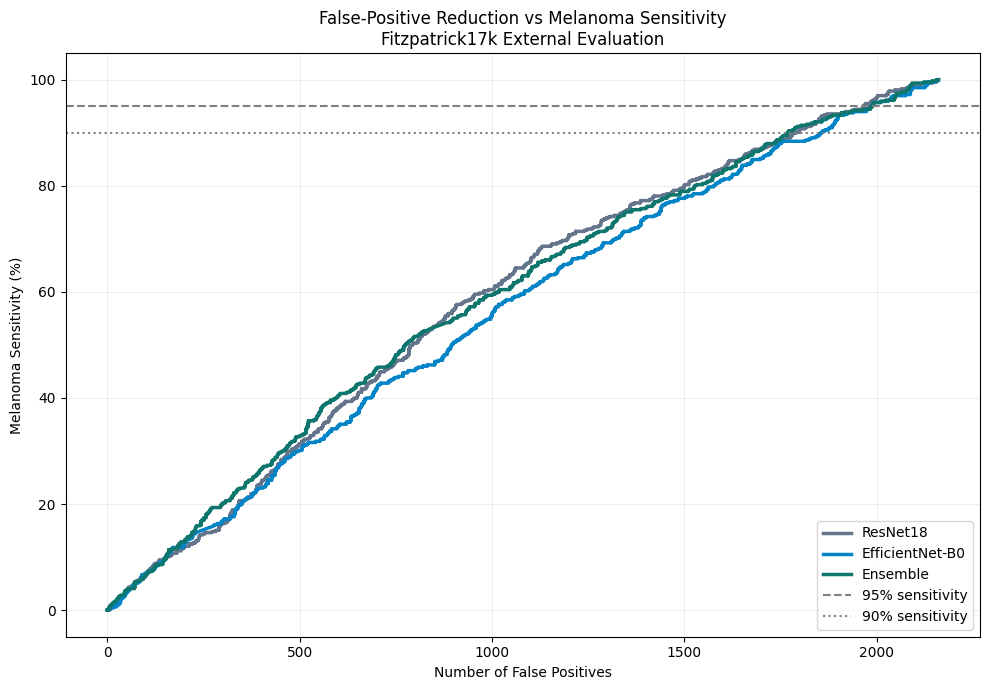


Saved results to: /kaggle/working/poster_figures


In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score, average_precision_score

CSV_PATH = "/kaggle/working/fitzpatrick_model_predictions.csv"
OUT = "/kaggle/working/poster_figures"
os.makedirs(OUT, exist_ok=True)

df = pd.read_csv(CSV_PATH)

y = df["target"].astype(int).to_numpy()

models = {
    "ResNet18": df["resnet_score"].to_numpy(dtype=float),
    "EfficientNet-B0": df["efficientnet_score"].to_numpy(dtype=float),
    "Ensemble": df["ensemble_score"].to_numpy(dtype=float)
}

assert len(df) == 2625
assert y.sum() == 465
assert all(np.isfinite(scores).all() for scores in models.values())

rows = []

for name, scores in models.items():

    # Every unique score is a possible classification boundary.
    thresholds = np.unique(np.concatenate([
        [0.011417324365],
        scores,
        [np.nextafter(scores.max(), np.inf)]
    ]))

    for threshold in thresholds:
        pred = scores >= threshold

        tp = int(np.sum((pred == 1) & (y == 1)))
        fn = int(np.sum((pred == 0) & (y == 1)))
        fp = int(np.sum((pred == 1) & (y == 0)))
        tn = int(np.sum((pred == 0) & (y == 0)))

        rows.append({
            "Model": name,
            "Threshold": threshold,
            "Sensitivity": tp / (tp + fn),
            "Specificity": tn / (tn + fp),
            "False_Positives": fp,
            "False_Negatives": fn
        })

tradeoff = pd.DataFrame(rows)

print("===== EXTERNAL MODEL PERFORMANCE =====")

for name, scores in models.items():
    print(
        f"{name:18s} "
        f"ROC-AUC={roc_auc_score(y, scores):.4f}  "
        f"PR-AUC={average_precision_score(y, scores):.4f}"
    )

print("\n===== EXPLORATORY THRESHOLD COMPARISON =====")

summary = []

for name in models:
    subset = tradeoff[tradeoff["Model"] == name]

    for target in [0.95, 0.90, 0.85]:
        eligible = subset[
            subset["Sensitivity"] >= target
        ]

        if eligible.empty:
            continue

        best = eligible.sort_values(
            ["False_Positives", "False_Negatives"],
            ascending=[True, True]
        ).iloc[0]

        summary.append({
            "Model": name,
            "Target Sensitivity": f"{target:.0%}",
            "Threshold": best["Threshold"],
            "Sensitivity": best["Sensitivity"],
            "Specificity": best["Specificity"],
            "False Positives": int(best["False_Positives"]),
            "False Negatives": int(best["False_Negatives"])
        })

summary_df = pd.DataFrame(summary)
display(summary_df.round(4))

summary_df.to_csv(
    f"{OUT}/threshold_comparison.csv",
    index=False
)

# Plot sensitivity versus false positives
plt.figure(figsize=(10, 7))

colors = {
    "ResNet18": "#64748B",
    "EfficientNet-B0": "#0284C7",
    "Ensemble": "#0F766E"
}

for name in models:
    subset = tradeoff[
        tradeoff["Model"] == name
    ].sort_values("False_Positives")

    plt.plot(
        subset["False_Positives"],
        subset["Sensitivity"] * 100,
        linewidth=2.5,
        color=colors[name],
        label=name
    )

plt.axhline(
    95, color="gray", linestyle="--",
    label="95% sensitivity"
)

plt.axhline(
    90, color="gray", linestyle=":",
    label="90% sensitivity"
)

plt.xlabel("Number of False Positives")
plt.ylabel("Melanoma Sensitivity (%)")
plt.title(
    "False-Positive Reduction vs Melanoma Sensitivity\n"
    "Fitzpatrick17k External Evaluation"
)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    f"{OUT}/05_false_positive_tradeoff.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved results to:", OUT)

===== SKIN-TONE MODEL PERFORMANCE =====


,Skin Group,Model,Images,Melanoma,Benign,ROC-AUC,PR-AUC
0,I-II,ResNet18,1405,290,1115,0.5620,0.2351
1,I-II,EfficientNet-B0,1405,290,1115,0.5760,0.2461
2,I-II,Ensemble,1405,290,1115,0.5771,0.2549
3,III-IV,ResNet18,974,132,842,0.5992,0.1752
4,III-IV,EfficientNet-B0,974,132,842,0.5302,0.1529
5,III-IV,Ensemble,974,132,842,0.5796,0.1737
6,V-VI,ResNet18,246,43,203,0.6286,0.2982
7,V-VI,EfficientNet-B0,246,43,203,0.4838,0.1810
8,V-VI,Ensemble,246,43,203,0.5846,0.2419


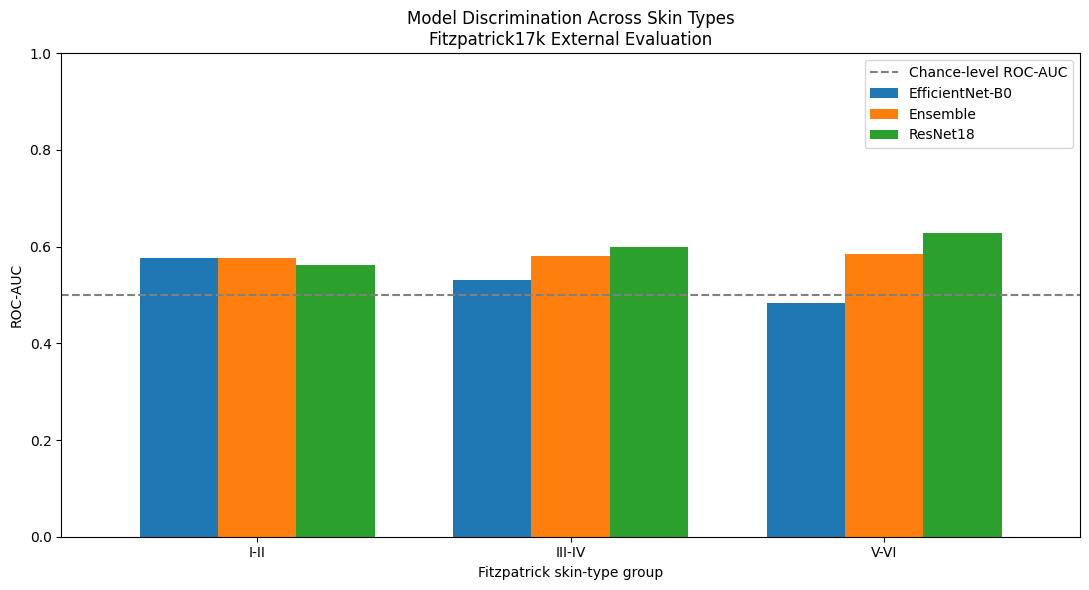


===== BACKGROUND ARTIFACT CHECK =====


,count,mean,median,max
skin_group,,,,
I-II,1405,0.3536,0.2653,1.0
III-IV,974,0.2508,0.1675,1.0
V-VI,246,0.4353,0.4170,1.0



Black-pixel ratio by prediction outcome:


,count,mean,median
error_type,,,
Correct,644,0.2598,0.1598
False Negative,27,0.0710,0.0247
False Positive,1954,0.3475,0.2605


In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score

PRED_PATH = "/kaggle/working/fitzpatrick_model_predictions.csv"
ARTIFACT_PATH = "/kaggle/working/fitzpatrick_artifact_analysis.csv"
OUT = "/kaggle/working/poster_figures"

os.makedirs(OUT, exist_ok=True)

df = pd.read_csv(PRED_PATH)

groups = ["I-II", "III-IV", "V-VI"]
model_cols = {
    "ResNet18": "resnet_score",
    "EfficientNet-B0": "efficientnet_score",
    "Ensemble": "ensemble_score"
}

rows = []

for group in groups:
    sub = df[df["skin_group"] == group]

    for model_name, score_col in model_cols.items():
        y = sub["target"].astype(int)
        scores = sub[score_col].astype(float)

        rows.append({
            "Skin Group": group,
            "Model": model_name,
            "Images": len(sub),
            "Melanoma": int(y.sum()),
            "Benign": int((1 - y).sum()),
            "ROC-AUC": roc_auc_score(y, scores),
            "PR-AUC": average_precision_score(y, scores)
        })

metrics = pd.DataFrame(rows)

print("===== SKIN-TONE MODEL PERFORMANCE =====")
display(metrics.round(4))

# ROC-AUC comparison across skin groups
pivot = metrics.pivot(
    index="Skin Group",
    columns="Model",
    values="ROC-AUC"
).reindex(groups)

ax = pivot.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

ax.axhline(
    0.5,
    color="gray",
    linestyle="--",
    label="Chance-level ROC-AUC"
)

ax.set_ylim(0, 1)
ax.set_ylabel("ROC-AUC")
ax.set_xlabel("Fitzpatrick skin-type group")
ax.set_title(
    "Model Discrimination Across Skin Types\n"
    "Fitzpatrick17k External Evaluation"
)

plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()

plt.savefig(
    f"{OUT}/06_skin_tone_roc_auc.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

metrics.to_csv(
    f"{OUT}/skin_tone_auc_comparison.csv",
    index=False
)

# Inspect existing artifact analysis
if os.path.isfile(ARTIFACT_PATH):
    artifact = pd.read_csv(ARTIFACT_PATH)

    if "black_pixel_ratio" in artifact.columns:
        print("\n===== BACKGROUND ARTIFACT CHECK =====")

        display(
            artifact.groupby("skin_group")["black_pixel_ratio"]
            .agg(["count", "mean", "median", "max"])
            .round(4)
        )

        print("\nBlack-pixel ratio by prediction outcome:")

        display(
            artifact.groupby("error_type")["black_pixel_ratio"]
            .agg(["count", "mean", "median"])
            .round(4)
        )

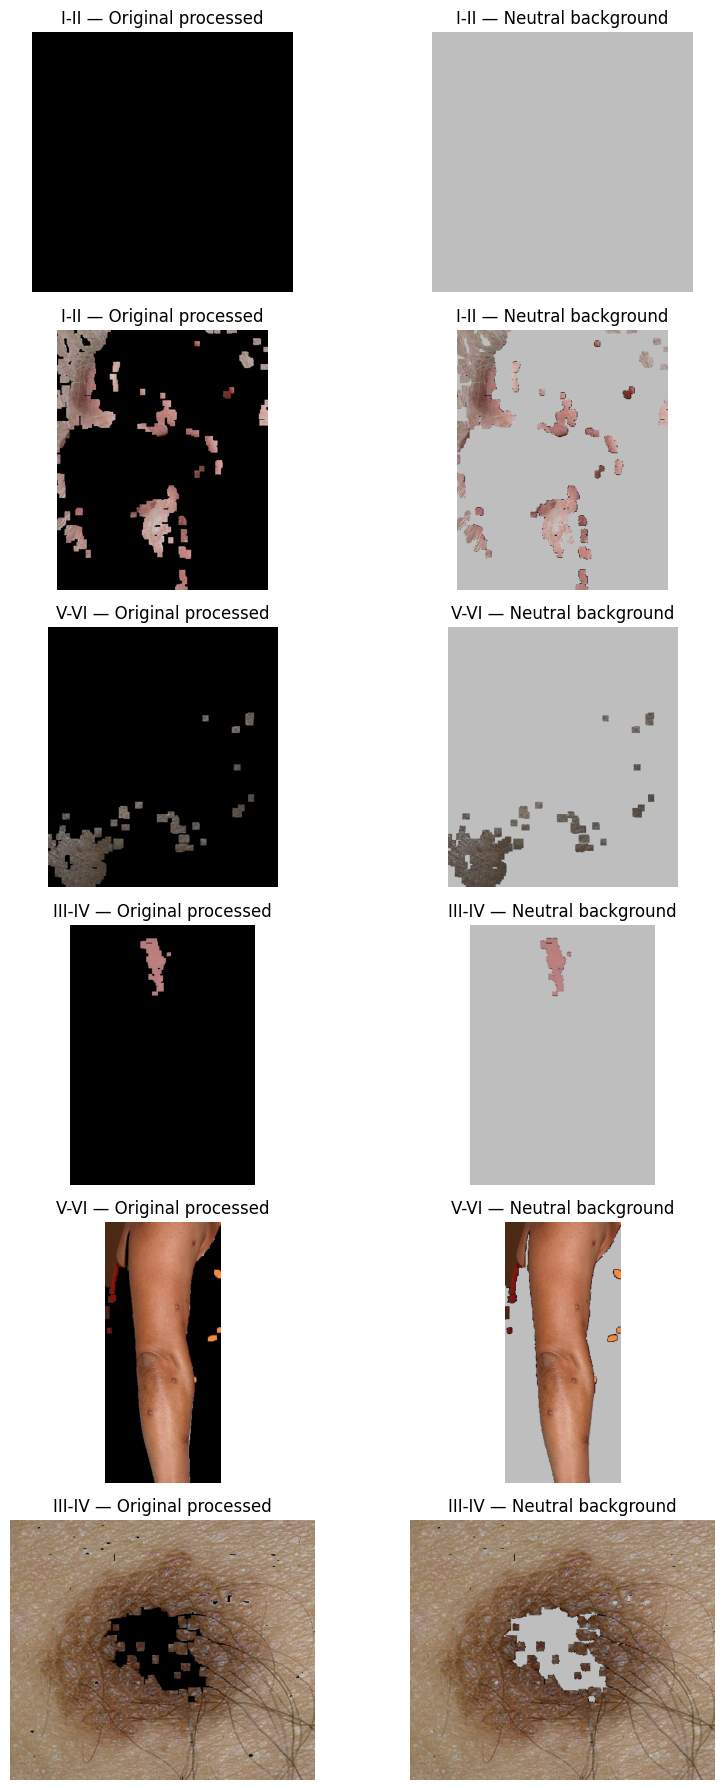

In [6]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    "/kaggle/working/fitzpatrick_model_predictions.csv"
)

sample = (
    df.groupby("skin_group", group_keys=False)
      .head(2)
      .reset_index(drop=True)
)

fig, axes = plt.subplots(
    len(sample), 2,
    figsize=(9, 3 * len(sample))
)

for i, row in sample.iterrows():

    img = cv2.imread(row["image_path"])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Identify nearly black pixels
    mask = np.all(img < 12, axis=2)

    # Experimental neutral background
    modified = img.copy()
    modified[mask] = [190, 190, 190]

    axes[i, 0].imshow(img)
    axes[i, 0].set_title(
        f"{row['skin_group']} — Original processed"
    )

    axes[i, 1].imshow(modified)
    axes[i, 1].set_title(
        f"{row['skin_group']} — Neutral background"
    )

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()